In [2]:
import pandas as pd
import numpy as np
import re
from datetime import datetime
import os
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import folium
from folium.plugins import HeatMap
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

ModuleNotFoundError: No module named 'pandas'

In [ ]:
# Load Listings
listings_df = pd.read_csv('listings_final.csv', low_memory=False)
print(f"✓ Loaded listings_final.csv: {len(listings_df):,} rows")


✓ Loaded listings_final.csv: 80,739 rows


In [ ]:
# Load Neighborhood
neighborhood_df = pd.read_csv('neighborhood_final.csv')
print(f"✓ Loaded neighborhood_final.csv: {len(neighborhood_df):,} rows")

✓ Loaded neighborhood_final.csv: 589 rows


In [ ]:
"""# Load Reviews in chunks
print("Loading reviews (this may take a moment)...")
chunk_size = 100000
reviews_chunks = []

for chunk in pd.read_csv('reviews_final.csv', chunksize=chunk_size, low_memory=False):
    reviews_chunks.append(chunk)

reviews_df = pd.concat(reviews_chunks, ignore_index=True)
print(f"✓ Loaded reviews_final.csv: {len(reviews_df):,} rows")"""

'# Load Reviews in chunks\nprint("Loading reviews (this may take a moment)...")\nchunk_size = 100000\nreviews_chunks = []\n\nfor chunk in pd.read_csv(\'reviews_final.csv\', chunksize=chunk_size, low_memory=False):\n    reviews_chunks.append(chunk)\n\nreviews_df = pd.concat(reviews_chunks, ignore_index=True)\nprint(f"✓ Loaded reviews_final.csv: {len(reviews_df):,} rows")'

In [ ]:
reviews_df = pd.read_csv("reviews_combined (1).csv", engine='python') #, on_bad_lines='skip')
print(f"✓ Loaded reviews_final.csv: {len(reviews_df):,} rows")

✓ Loaded reviews_final.csv: 3,715,598 rows


In [ ]:
# Make a copy
listings_df1 = listings_df.copy()
initial_rows = len(listings_df1)
print(initial_rows)

80739


In [ ]:
# Fill missing categorical values
listings_df1['host_name'] = listings_df1['host_name'].fillna('Unknown')
listings_df1['neighbourhood_group'] = listings_df1['neighbourhood_group'].fillna('Unknown')
listings_df1['neighbourhood'] = listings_df1['neighbourhood'].fillna('Unknown')
listings_df1['license'] = listings_df1['license'].fillna('No License')

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,2,1945,2025-03-09,10.18,2,304,70,No License
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,30,103,2024-10-20,0.58,2,179,4,No License
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,1,587,2025-02-23,3.23,1,0,23,No License
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,4,415,2024-07-21,2.76,2,330,29,No License
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,31,92,2024-09-04,0.52,1,285,2,No License


In [ ]:
Exempt = listings_df1[listings_df1['license'].str.contains('exempt', case=False, na=False)]

In [ ]:
Exempt['license'].unique()

array(['Exempt', 'Exempt - This listing is a bed and breakfast',
       'Exempt - This listing is a transient occupancy residential structure',
       'Exempt - This listing is a hotel or motel'], dtype=object)

In [ ]:
# listings_df1['license'] = listings_df1['license'].replace(r'(?i)^exempt$', 'exempt', regex=True)

In [ ]:
# Clean price
listings_df1['price'] = listings_df1['price'].astype(str).str.replace('$', '').str.replace(',', '')
listings_df1['price'] = pd.to_numeric(listings_df1['price'], errors='coerce')
listings_df1 = listings_df1[(listings_df1['price'] >= 10) & (listings_df1['price'] <= 10000)]
listings_df1['price_log'] = np.log1p(listings_df1['price'])
listings_df1['price_normalized'] = (listings_df1['price_log'] - listings_df1['price_log'].mean()) / listings_df1['price_log'].std()
listings_df1 = listings_df1[(listings_df1['price_normalized'] >= -3) & (listings_df1['price_normalized'] <= 3)]
listings_df1['price_normalized'] = (listings_df1['price_log'] - listings_df1['price_log'].mean()) / listings_df1['price_log'].std()

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,2,1945,2025-03-09,10.18,2,304,70,No License,5.056246,-0.130497
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,30,103,2024-10-20,0.58,2,179,4,No License,4.330733,-1.045108
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,1,587,2025-02-23,3.23,1,0,23,No License,4.919981,-0.302278
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,4,415,2024-07-21,2.76,2,330,29,No License,5.318120,0.199632
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,31,92,2024-09-04,0.52,1,285,2,No License,4.663439,-0.625686


#### Listings Data Cleaning

In [ ]:
# Clean numeric columns
numeric_columns = ['minimum_nights', 'number_of_reviews', 'reviews_per_month',
                   'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm']

In [ ]:
for col in numeric_columns:
    listings_df1[col] = pd.to_numeric(listings_df1[col], errors='coerce')
    if 'rate' in col or 'per_month' in col:
        listings_df1[col] = listings_df1[col].fillna(listings_df1[col].median())
    else:
        listings_df1[col] = listings_df1[col].fillna(0)

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,2,1945,2025-03-09,10.18,2,304,70,No License,5.056246,-0.130497
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,30,103,2024-10-20,0.58,2,179,4,No License,4.330733,-1.045108
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,1,587,2025-02-23,3.23,1,0,23,No License,4.919981,-0.302278
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,4,415,2024-07-21,2.76,2,330,29,No License,5.318120,0.199632
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,31,92,2024-09-04,0.52,1,285,2,No License,4.663439,-0.625686


In [ ]:
# Clean coordinates
listings_df1['latitude'] = pd.to_numeric(listings_df1['latitude'], errors='coerce')
listings_df1['longitude'] = pd.to_numeric(listings_df1['longitude'], errors='coerce')
listings_df1 = listings_df1.dropna(subset=['latitude', 'longitude'])
listings_df1 = listings_df1[(listings_df1['latitude'] >= -90) & (listings_df1['latitude'] <= 90)]
listings_df1 = listings_df1[(listings_df1['longitude'] >= -180) & (listings_df1['longitude'] <= 180)]

In [ ]:
# Clean text
listings_df1['name'] = listings_df1['name'].astype(str).str.strip().replace('nan', 'Unnamed Listing')
listings_df1['host_name'] = listings_df1['host_name'].astype(str).str.strip().replace('nan', 'Unknown')

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,2,1945,2025-03-09,10.18,2,304,70,No License,5.056246,-0.130497
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,30,103,2024-10-20,0.58,2,179,4,No License,4.330733,-1.045108
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,1,587,2025-02-23,3.23,1,0,23,No License,4.919981,-0.302278
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,4,415,2024-07-21,2.76,2,330,29,No License,5.318120,0.199632
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,31,92,2024-09-04,0.52,1,285,2,No License,4.663439,-0.625686


In [ ]:
# Clean room_type
room_type_mapping = {
    'Entire home/apt': 'Entire home/apt',
    'Private room': 'Private room',
    'Shared room': 'Shared room',
    'Hotel room': 'Hotel room'
}
listings_df1['room_type'] = listings_df1['room_type'].map(room_type_mapping).fillna('Other')

listings_df1['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room', 'Hotel room'],
      dtype=object)

In [ ]:
# Parse last review
listings_df1['last_review'] = pd.to_datetime(listings_df1['last_review'], errors='coerce')
listings_df1['last_review'].dtype

dtype('<M8[ns]')

In [ ]:
# Drop duplicates
listings_df1 = listings_df1.drop_duplicates(subset=['id'])

print(f"✓ Dropped {initial_rows - len(listings_df1)} duplicate rows")

✓ Dropped 15842 duplicate rows


# Add features

In [ ]:
listings_df1['days_since_last_review'] = (pd.Timestamp.now() - listings_df1['last_review']).dt.days
listings_df1['days_since_last_review'] = listings_df1['days_since_last_review'].fillna(9999)

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized,days_since_last_review
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,...,1945,2025-03-09,10.18,2,304,70,No License,5.056246,-0.130497,157.0
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,...,103,2024-10-20,0.58,2,179,4,No License,4.330733,-1.045108,297.0
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,...,587,2025-02-23,3.23,1,0,23,No License,4.919981,-0.302278,171.0
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,...,415,2024-07-21,2.76,2,330,29,No License,5.318120,0.199632,388.0
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,...,92,2024-09-04,0.52,1,285,2,No License,4.663439,-0.625686,343.0


In [ ]:
price_percentiles = listings_df1['price_normalized'].quantile([0.2, 0.4, 0.6, 0.8])
listings_df1['price_category'] = pd.cut(listings_df1['price_normalized'],
    bins=[float('-inf'), price_percentiles[0.2], price_percentiles[0.4],
          price_percentiles[0.6], price_percentiles[0.8], float('inf')],
    labels=['Budget', 'Economy', 'Mid-range', 'Premium', 'Luxury'])

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized,days_since_last_review,price_category
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,...,2025-03-09,10.18,2,304,70,No License,5.056246,-0.130497,157.0,Mid-range
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,...,2024-10-20,0.58,2,179,4,No License,4.330733,-1.045108,297.0,Budget
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,...,2025-02-23,3.23,1,0,23,No License,4.919981,-0.302278,171.0,Economy
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,...,2024-07-21,2.76,2,330,29,No License,5.318120,0.199632,388.0,Premium
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,...,2024-09-04,0.52,1,285,2,No License,4.663439,-0.625686,343.0,Economy


In [ ]:
listings_df1['review_activity'] = pd.cut(listings_df1['number_of_reviews'],
    bins=[0, 10, 50, 200, float('inf')],
    labels=['Low', 'Medium', 'High', 'Very High'])

listings_df1.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_log,price_normalized,days_since_last_review,price_category,review_activity
0,8357,Mushroom dome retreat & Land of paradise suite,24281,Katherine,Unknown,Unincorporated Areas,37.00939,-121.88547,Private room,156.0,...,10.18,2,304,70,No License,5.056246,-0.130497,157.0,Mid-range,Very High
1,11879,Sunny room close to beach and parks,44764,Steven,Unknown,Unincorporated Areas,36.98048,-121.88129,Private room,75.0,...,0.58,2,179,4,No License,4.330733,-1.045108,297.0,Budget,High
2,24548,Mini Guest Suite with Private Entrance,99532,Kerstin,Unknown,City of Santa Cruz,36.97191,-121.99735,Entire home/apt,136.0,...,3.23,1,0,23,No License,4.919981,-0.302278,171.0,Economy,Very High
3,31721,Surf cottage Pleasure Point walk to surf/ coffee,136376,Annie,Unknown,City of Capitola,36.95845,-121.97194,Entire home/apt,203.0,...,2.76,2,330,29,No License,5.318120,0.199632,388.0,Premium,Very High
4,37791,The GetAway,162553,Katie,Unknown,City of Santa Cruz,36.97425,-122.00706,Entire home/apt,105.0,...,0.52,1,285,2,No License,4.663439,-0.625686,343.0,Economy,High


In [ ]:
cleaned_listings = listings_df1
print(f"✓ Cleaned listings: {len(cleaned_listings):,} rows")

✓ Cleaned listings: 64,897 rows


#### Neighbourhood Data Cleaning

In [ ]:
neighborhood_df1 = neighborhood_df.copy()
initial_rows = len(neighborhood_df1)
print(initial_rows)

589


In [ ]:
neighborhood_df1['neighbourhood_group'] = neighborhood_df1['neighbourhood_group'].fillna('Unknown')
neighborhood_df1 = neighborhood_df1.dropna(subset=['neighbourhood'])
neighborhood_df1['neighbourhood_group'] = neighborhood_df1['neighbourhood_group'].astype(str).str.strip()
neighborhood_df1['neighbourhood'] = neighborhood_df1['neighbourhood'].astype(str).str.strip()

In [ ]:
neighborhood_df1 = neighborhood_df1.drop_duplicates()
print(f"✓ Dropped {initial_rows - len(neighborhood_df1)} duplicate rows")

✓ Dropped 8 duplicate rows


In [ ]:
cleaned_neighborhood = neighborhood_df1
print(f"✓ Cleaned neighborhood: {len(cleaned_neighborhood):,} rows")

✓ Cleaned neighborhood: 581 rows


#### Review Data Cleaning

In [ ]:
reviews_df1 = reviews_df.copy()
initial_rows = len(reviews_df1)

In [ ]:
# Remove rows missing IDs
reviews_df1 = reviews_df1.dropna(subset=['listing_id', 'reviewer_id'])


reviews_df1.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,4952,6560,2009-08-02,25672,Diane,Staying with Mei Lin and Ross at the Butterfly...
1,4952,8953,2009-09-04,27901,Michaela,I stayed with Mei Lin and Ross during a confer...
2,4952,13779,2009-10-16,33939,Mark,What a wonderful place to stay. Wonderful peop...
3,4952,19790,2009-12-10,55537,David,"Convenient & easy-going, which is what I needed."
4,4952,51096,2010-06-08,131240,SiNae,"Warm and friendly folks, very helpful! Very co..."


In [ ]:
reviews_df1['reviewer_name'] = reviews_df1['reviewer_name'].fillna('Anonymous')
reviews_df1['reviewer_name'] = reviews_df1['reviewer_name'].astype(str).str.strip()
reviews_df1['reviewer_name'].unique()

array(['Diane', 'Michaela', 'Mark', ..., 'Aalonie', 'Limamou', 'Wyntesha'],
      dtype=object)

In [ ]:
# Convert and filter date
reviews_df1['date'] = pd.to_datetime(reviews_df1['date'], errors='coerce')
reviews_df1 = reviews_df1.dropna(subset=['date'])
reviews_df1 = reviews_df1[reviews_df1['date'] <= pd.Timestamp.now()]

reviews_df1.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,4952,6560,2009-08-02,25672,Diane,Staying with Mei Lin and Ross at the Butterfly...
1,4952,8953,2009-09-04,27901,Michaela,I stayed with Mei Lin and Ross during a confer...
2,4952,13779,2009-10-16,33939,Mark,What a wonderful place to stay. Wonderful peop...
3,4952,19790,2009-12-10,55537,David,"Convenient & easy-going, which is what I needed."
4,4952,51096,2010-06-08,131240,SiNae,"Warm and friendly folks, very helpful! Very co..."


In [ ]:
# Clean comments
reviews_df1['reviewer_name'] = reviews_df1['reviewer_name'].astype(str).str.strip()
reviews_df1['comments'] = reviews_df1['comments'].astype(str).str.strip()
reviews_df1 = reviews_df1[~reviews_df1['comments'].isin(['', 'nan'])]

reviews_df1.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,4952,6560,2009-08-02,25672,Diane,Staying with Mei Lin and Ross at the Butterfly...
1,4952,8953,2009-09-04,27901,Michaela,I stayed with Mei Lin and Ross during a confer...
2,4952,13779,2009-10-16,33939,Mark,What a wonderful place to stay. Wonderful peop...
3,4952,19790,2009-12-10,55537,David,"Convenient & easy-going, which is what I needed."
4,4952,51096,2010-06-08,131240,SiNae,"Warm and friendly folks, very helpful! Very co..."


In [ ]:
def clean_comment(text):
    text = re.sub(r'<[^>]+>', '', str(text))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

reviews_df1['comments_clean'] = reviews_df1['comments'].apply(clean_comment)
reviews_df1 = reviews_df1[reviews_df1['comments_clean'].str.len() >= 10]

In [ ]:
# Drop duplicates
reviews_df1 = reviews_df1.drop_duplicates(subset=['id'])

Add features

In [ ]:
reviews_df1['review_year'] = reviews_df1['date'].dt.year
reviews_df1['review_month'] = reviews_df1['date'].dt.month
reviews_df1['review_quarter'] = reviews_df1['date'].dt.quarter
reviews_df1['comment_length'] = reviews_df1['comments_clean'].str.len()
reviews_df1['comment_category'] = pd.cut(reviews_df1['comment_length'],
                                bins=[0, 50, 200, 500, float('inf')],
                                labels=['Short', 'Medium', 'Long', 'Very Long'])

reviews_df1.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments,comments_clean,review_year,review_month,review_quarter,comment_length,comment_category
0,4952,6560,2009-08-02,25672,Diane,Staying with Mei Lin and Ross at the Butterfly...,Staying with Mei Lin and Ross at the Butterfly...,2009,8,3,666,Very Long
1,4952,8953,2009-09-04,27901,Michaela,I stayed with Mei Lin and Ross during a confer...,I stayed with Mei Lin and Ross during a confer...,2009,9,3,459,Long
2,4952,13779,2009-10-16,33939,Mark,What a wonderful place to stay. Wonderful peop...,What a wonderful place to stay. Wonderful peop...,2009,10,4,311,Long
3,4952,19790,2009-12-10,55537,David,"Convenient & easy-going, which is what I needed.","Convenient & easy-going, which is what I needed.",2009,12,4,48,Short
4,4952,51096,2010-06-08,131240,SiNae,"Warm and friendly folks, very helpful! Very co...","Warm and friendly folks, very helpful! Very co...",2010,6,2,184,Medium


In [ ]:
cleaned_reviews = reviews_df1
print(f"✓ Cleaned reviews: {len(cleaned_reviews):,} rows")

✓ Cleaned reviews: 3,671,697 rows


Merge Cleaned Data

In [ ]:
# Merge reviews with listings
merged_df = pd.merge(
    cleaned_reviews,
    cleaned_listings[['id', 'name', 'host_name', 'neighbourhood_group',
                      'neighbourhood', 'room_type', 'price', 'price_log', 'price_normalized',
                      'latitude', 'longitude']],
    left_on='listing_id', right_on='id', how='left', suffixes=('_review', '_listing')
)

# Merge with neighborhood data
merged_df = pd.merge(
    merged_df,
    cleaned_neighborhood,
    on=['neighbourhood_group', 'neighbourhood'],
    how='left'
)

print(f"✓ Merged data: {len(merged_df):,} rows, {len(merged_df.columns)} columns")


✓ Merged data: 3,671,697 rows, 23 columns


In [ ]:
"""# Save to CSV
merged_df.to_csv('Airbnb_Merge.csv', index=False)
from google.colab import files
files.download('Airbnb_Merge.csv')"""

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Data Cleaning Summary

In [ ]:
print("\n=== Summary ===")
print(f"Listings cleaned: {len(cleaned_listings):,}")
print(f"Neighborhoods cleaned: {len(cleaned_neighborhood):,}")
print(f"Reviews cleaned: {len(cleaned_reviews):,}")
print(f"Final merged dataset: {len(merged_df):,} rows, {len(merged_df.columns)} columns")



=== Summary ===
Listings cleaned: 64,897
Neighborhoods cleaned: 581
Reviews cleaned: 3,671,697
Final merged dataset: 3,671,697 rows, 23 columns


Price Stats

In [ ]:
# Use the existing listings dataframe
listings = listings_df1.copy()

print("📋 LISTINGS DATA SUMMARY")
print("-" * 40)
print(f"Total Listings: {len(listings):,}")
print(f"Total Columns: {len(listings.columns)}")

# Price Analysis
print(f"\n💰 Price Analysis:")
print(f"  Average Price: ${listings['price'].mean():.2f}")
print(f"  Median Price: ${listings['price'].median():.2f}")
print(f"  Minimum Price: ${listings['price'].min():.2f}")
print(f"  Maximum Price: ${listings['price'].max():.2f}")


📋 LISTINGS DATA SUMMARY
----------------------------------------
Total Listings: 64,897
Total Columns: 23

💰 Price Analysis:
  Average Price: $244.78
  Median Price: $165.00
  Minimum Price: $14.00
  Maximum Price: $2211.00


Normalized Price Stats

In [ ]:
# Log-normalized price stats
print(f"\n📊 Z-Score Normalized Price Analysis:")
print(f"  Average Normalized Price: {listings['price_normalized'].mean():.3f}")
print(f"  Standard Deviation: {listings['price_normalized'].std():.3f}")
print(f"  Min Normalized Price: {listings['price_normalized'].min():.3f}")
print(f"  Max Normalized Price: {listings['price_normalized'].max():.3f}")



📊 Z-Score Normalized Price Analysis:
  Average Normalized Price: -0.000
  Standard Deviation: 1.000
  Min Normalized Price: -3.091
  Max Normalized Price: 3.204


In [ ]:
# Room type distribution
print(f"\n🏠 Room Type Distribution:")
room_type_counts = listings['room_type'].value_counts()
for room_type, count in room_type_counts.items():
    percentage = (count / len(listings)) * 100
    print(f"  {room_type}: {count:,} ({percentage:.1f}%)")


🏠 Room Type Distribution:
  Entire home/apt: 49,008 (75.5%)
  Private room: 14,976 (23.1%)
  Hotel room: 469 (0.7%)
  Shared room: 444 (0.7%)


In [ ]:
# Price categories
print(f"\n💎 Price Categories:")
if 'price_category' in listings.columns:
    price_cat_counts = listings['price_category'].value_counts()
    for category, count in price_cat_counts.items():
        percentage = (count / len(listings)) * 100
        print(f"  {category}: {count:,} ({percentage:.1f}%)")


💎 Price Categories:
  Budget: 13,131 (20.2%)
  Mid-range: 12,946 (19.9%)
  Luxury: 12,944 (19.9%)
  Economy: 12,943 (19.9%)
  Premium: 12,933 (19.9%)


In [ ]:
# Review activity
print(f"\n📝 Review Activity Levels:")
if 'review_activity' in listings.columns:
    review_activity_counts = listings['review_activity'].value_counts()
    for activity, count in review_activity_counts.items():
        percentage = (count / len(listings)) * 100
        print(f"  {activity}: {count:,} ({percentage:.1f}%)")


📝 Review Activity Levels:
  Low: 18,270 (28.2%)
  Medium: 15,382 (23.7%)
  High: 12,742 (19.6%)
  Very High: 4,492 (6.9%)


Neighbourhood Summary

In [ ]:
# Use existing neighborhood dataframe
neighborhood = neighborhood_df1.copy()

In [ ]:
print(f"\n🏘️ NEIGHBORHOOD DATA SUMMARY")
print("-" * 40)
print(f"Total Neighborhoods: {len(neighborhood):,}")
print(f"Neighborhood Groups: {neighborhood['neighbourhood_group'].nunique()}")


🏘️ NEIGHBORHOOD DATA SUMMARY
----------------------------------------
Total Neighborhoods: 581
Neighborhood Groups: 4


In [ ]:
# Top 10 neighborhoods by listings
print(f"\n📍 Top 10 Neighborhoods by Listings:")
top_neighborhoods = listings['neighbourhood'].value_counts().head(10)
for i, (name, count) in enumerate(top_neighborhoods.items(), 1):
    percentage = (count / len(listings)) * 100
    print(f"  {i:2d}. {name}: {count:,} listings ({percentage:.1f}%)")


📍 Top 10 Neighborhoods by Listings:
   1. San Jose: 2,442 listings (3.8%)
   2. Mission Bay: 1,632 listings (2.5%)
   3. Unincorporated Areas: 1,586 listings (2.4%)
   4. Long Beach: 1,482 listings (2.3%)
   5. Hollywood: 1,296 listings (2.0%)
   6. Venice: 1,187 listings (1.8%)
   7. West Hollywood: 1,057 listings (1.6%)
   8. Santa Monica: 1,036 listings (1.6%)
   9. Pacific Beach: 1,011 listings (1.6%)
  10. Downtown: 973 listings (1.5%)


In [ ]:
print(f"\n✅ DATA QUALITY METRICS")
print("-" * 40)

missing_listings = listings.isnull().sum()
missing_cols = missing_listings[missing_listings > 0]

if len(missing_cols) > 0:
    print("Missing values in Listings:")
    for col, missing in missing_cols.items():
        percentage = (missing / len(listings)) * 100
        print(f"  {col}: {missing:,} ({percentage:.1f}%)")
else:
    print("✓ No missing values in listings data!")


✅ DATA QUALITY METRICS
----------------------------------------
Missing values in Listings:
  last_review: 14,011 (21.6%)
  review_activity: 14,011 (21.6%)


In [ ]:
# Most expensive neighborhoods
avg_price_by_neighborhood = listings.groupby('neighbourhood')['price'].mean().sort_values(ascending=False)
print("Most Expensive Neighborhoods (Average Price):")
for i, (name, avg_price) in enumerate(avg_price_by_neighborhood.head(5).items(), 1):
    print(f"  {i}. {name}: ${avg_price:.2f}")

Most Expensive Neighborhoods (Average Price):
  1. Highland: $1043.50
  2. Bel-Air: $871.17
  3. Beverly Crest: $867.12
  4. Unincorporated Catalina Island: $844.78
  5. Hollywood Hills West: $779.68


In [ ]:
# Most active hosts
host_activity = listings.groupby('host_name')['number_of_reviews'].sum().sort_values(ascending=False)
print(f"\nMost Active Hosts (Total Reviews):")
for i, (host, reviews) in enumerate(host_activity.head(5).items(), 1):
    print(f"  {i}. {host}: {reviews:,} reviews")


Most Active Hosts (Total Reviews):
  1. Unknown: 46,969 reviews
  2. John: 30,407 reviews
  3. Michael: 28,467 reviews
  4. Jennifer: 21,026 reviews
  5. David: 20,047 reviews


In [ ]:
# Price distribution by room type
print(f"\nPrice Distribution by Room Type:")
room_price_stats = listings.groupby('room_type')['price'].agg(['mean', 'median', 'count']).round(2)
for room_type, stats in room_price_stats.iterrows():
    print(f"  {room_type}:")
    print(f"    Average: ${stats['mean']:.2f}")
    print(f"    Median: ${stats['median']:.2f}")
    print(f"    Count: {int(stats['count']):,}")


Price Distribution by Room Type:
  Entire home/apt:
    Average: $288.07
    Median: $200.00
    Count: 49,008
  Hotel room:
    Average: $399.90
    Median: $300.00
    Count: 469
  Private room:
    Average: $104.25
    Median: $72.00
    Count: 14,976
  Shared room:
    Average: $43.69
    Median: $34.00
    Count: 444


In [ ]:
print(f"\n📋 DATA SCHEMA")
print("-" * 40)

print("Listings Columns:")
for col in listings.columns:
    dtype = str(listings[col].dtype)
    print(f"  {col}: {dtype}")

print(f"\nNeighborhood Columns:")
for col in neighborhood.columns:
    dtype = str(neighborhood[col].dtype)
    print(f"  {col}: {dtype}")


📋 DATA SCHEMA
----------------------------------------
Listings Columns:
  id: int64
  name: object
  host_id: int64
  host_name: object
  neighbourhood_group: object
  neighbourhood: object
  latitude: float64
  longitude: float64
  room_type: object
  price: float64
  minimum_nights: int64
  number_of_reviews: int64
  last_review: datetime64[ns]
  reviews_per_month: float64
  calculated_host_listings_count: int64
  availability_365: int64
  number_of_reviews_ltm: int64
  license: object
  price_log: float64
  price_normalized: float64
  days_since_last_review: float64
  price_category: category
  review_activity: category

Neighborhood Columns:
  neighbourhood_group: object
  neighbourhood: object


Price Analysis

📊 Analyzing Price Distributions


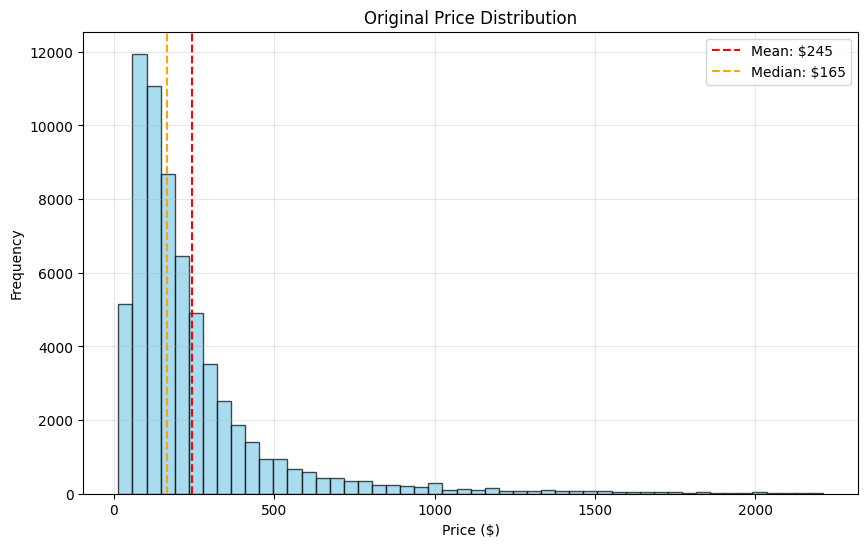

In [ ]:
print("📊 Analyzing Price Distributions")
print("=" * 50)

# 1. Original Price Distribution
plt.figure(figsize=(10, 6))
plt.hist(listings_df1['price'], bins=50, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Original Price Distribution')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

# Add mean and median lines
mean_price = listings_df1['price'].mean()
median_price = listings_df1['price'].median()
plt.axvline(mean_price, color='red', linestyle='--', label=f'Mean: ${mean_price:.0f}')
plt.axvline(median_price, color='orange', linestyle='--', label=f'Median: ${median_price:.0f}')
plt.legend()

plt.show()

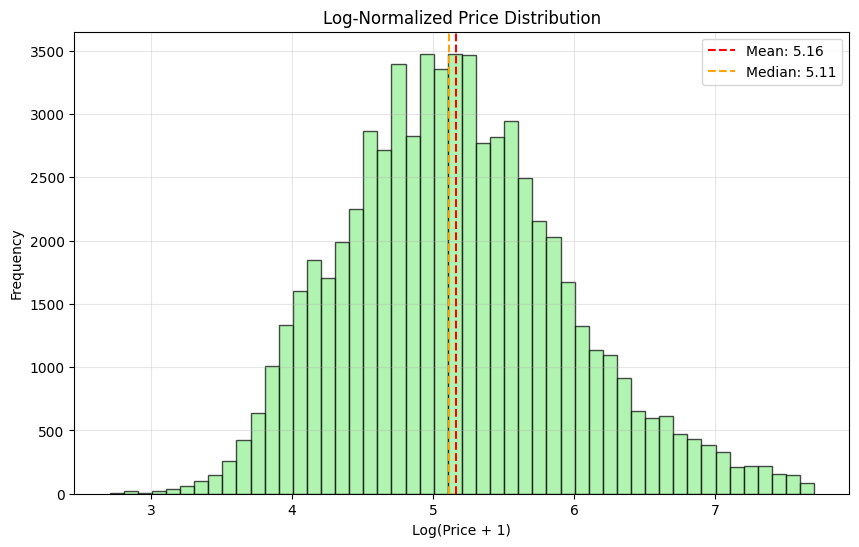

In [ ]:
# 2. Log-Normalized Price Distribution
plt.figure(figsize=(10, 6))
plt.hist(listings_df1['price_log'], bins=50, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Log-Normalized Price Distribution')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

mean_log = listings_df1['price_log'].mean()
median_log = listings_df1['price_log'].median()
plt.axvline(mean_log, color='red', linestyle='--', label=f'Mean: {mean_log:.2f}')
plt.axvline(median_log, color='orange', linestyle='--', label=f'Median: {median_log:.2f}')
plt.legend()

plt.show()

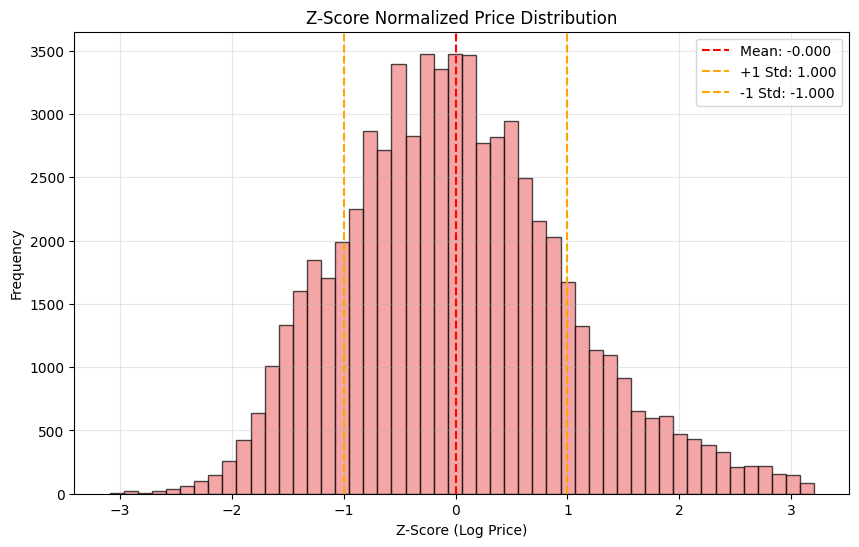

In [ ]:
# 3. Z-Score Normalized Price Distribution
plt.figure(figsize=(10, 6))
plt.hist(listings_df1['price_normalized'], bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Z-Score Normalized Price Distribution')
plt.xlabel('Z-Score (Log Price)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

mean_norm = listings_df1['price_normalized'].mean()
std_norm = listings_df1['price_normalized'].std()
plt.axvline(mean_norm, color='red', linestyle='--', label=f'Mean: {mean_norm:.3f}')
plt.axvline(mean_norm + std_norm, color='orange', linestyle='--', label=f'+1 Std: {mean_norm + std_norm:.3f}')
plt.axvline(mean_norm - std_norm, color='orange', linestyle='--', label=f'-1 Std: {mean_norm - std_norm:.3f}')
plt.legend()

plt.show()

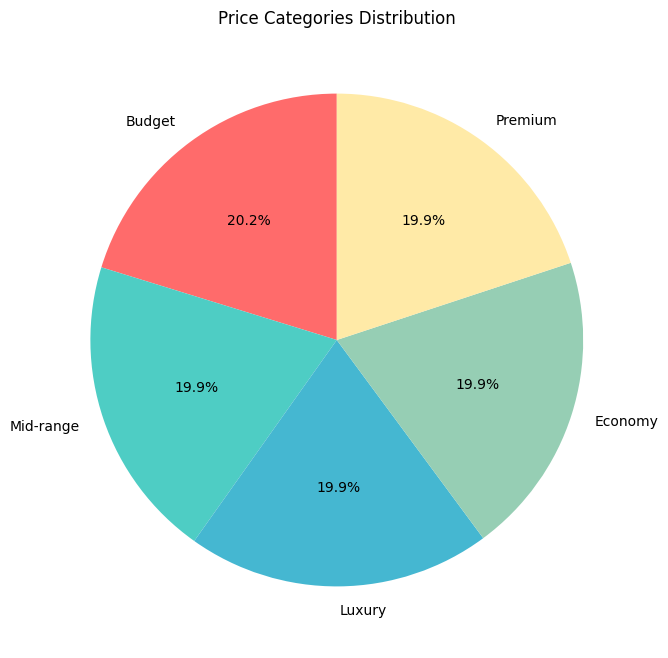

In [ ]:
# 4. Price Categories Pie Chart
price_cat_counts = listings_df1['price_category'].value_counts()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

plt.figure(figsize=(8, 8))
plt.pie(price_cat_counts.values, labels=price_cat_counts.index,
        autopct='%1.1f%%', colors=colors, startangle=90)
plt.title('Price Categories Distribution')

plt.show()

In [ ]:
print("\n📈 PRICE DISTRIBUTION STATISTICS")
print("-" * 40)

print("Original Price Statistics:")
print(f"  Mean: ${listings_df1['price'].mean():.2f}")
print(f"  Median: ${listings_df1['price'].median():.2f}")
print(f"  Standard Deviation: ${listings_df1['price'].std():.2f}")
print(f"  Skewness: {listings_df1['price'].skew():.3f}")
print(f"  Kurtosis: {listings_df1['price'].kurtosis():.3f}")

print("\nLog-Normalized Price Statistics:")
print(f"  Mean: {listings_df1['price_log'].mean():.3f}")
print(f"  Median: {listings_df1['price_log'].median():.3f}")
print(f"  Standard Deviation: {listings_df1['price_log'].std():.3f}")
print(f"  Skewness: {listings_df1['price_log'].skew():.3f}")
print(f"  Kurtosis: {listings_df1['price_log'].kurtosis():.3f}")

print("\nZ-Score Normalized Price Statistics:")
print(f"  Mean: {listings_df1['price_normalized'].mean():.3f}")
print(f"  Standard Deviation: {listings_df1['price_normalized'].std():.3f}")
print(f"  Min: {listings_df1['price_normalized'].min():.3f}")
print(f"  Max: {listings_df1['price_normalized'].max():.3f}")

print("\nPrice Categories:")
for category, count in price_cat_counts.items():
    percentage = (count / len(listings_df1)) * 100
    print(f"  {category}: {count:,} ({percentage:.1f}%)")

print("\n" + "=" * 50)
print("✅ Price analysis completed!")
print("📊 Log normalization has improved the price distribution for better statistical analysis!")



📈 PRICE DISTRIBUTION STATISTICS
----------------------------------------
Original Price Statistics:
  Mean: $244.78
  Median: $165.00
  Standard Deviation: $258.86
  Skewness: 3.255
  Kurtosis: 13.896

Log-Normalized Price Statistics:
  Mean: 5.160
  Median: 5.112
  Standard Deviation: 0.793
  Skewness: 0.378
  Kurtosis: 0.062

Z-Score Normalized Price Statistics:
  Mean: -0.000
  Standard Deviation: 1.000
  Min: -3.091
  Max: 3.204

Price Categories:
  Budget: 13,131 (20.2%)
  Mid-range: 12,946 (19.9%)
  Luxury: 12,944 (19.9%)
  Economy: 12,943 (19.9%)
  Premium: 12,933 (19.9%)

✅ Price analysis completed!
📊 Log normalization has improved the price distribution for better statistical analysis!


In [ ]:
print("\n📊 LISTINGS DATA OVERVIEW")
print("-" * 30)
print(f"Total Listings: {len(listings_df1):,}")
print(f"Columns: {len(listings_df1.columns)}")

valid_dates = listings_df1['last_review'].dropna()
if len(valid_dates) > 0:
    print(f"Date Range: {valid_dates.min().strftime('%Y-%m-%d')} to {valid_dates.max().strftime('%Y-%m-%d')}")
else:
    print("Date Range: No valid dates found")

print(f"\n💰 Price Statistics:")
print(f"  Average Price: ${listings_df1['price'].mean():.2f}")
print(f"  Median Price: ${listings_df1['price'].median():.2f}")
print(f"  Price Range: ${listings_df1['price'].min():.2f} - ${listings_df1['price'].max():.2f}")

print(f"\n🏠 Room Type Distribution:")
room_type_counts = listings_df1['room_type'].value_counts()
for room_type, count in room_type_counts.items():
    percentage = (count / len(listings_df1)) * 100
    print(f"  {room_type}: {count:,} ({percentage:.1f}%)")

print(f"\n💎 Price Categories:")
price_cat_counts = listings_df1['price_category'].value_counts()
for category, count in price_cat_counts.items():
    percentage = (count / len(listings_df1)) * 100
    print(f"  {category}: {count:,} ({percentage:.1f}%)")


📊 LISTINGS DATA OVERVIEW
------------------------------
Total Listings: 64,897
Columns: 23
Date Range: 2011-05-21 to 2025-06-29

💰 Price Statistics:
  Average Price: $244.78
  Median Price: $165.00
  Price Range: $14.00 - $2211.00

🏠 Room Type Distribution:
  Entire home/apt: 49,008 (75.5%)
  Private room: 14,976 (23.1%)
  Hotel room: 469 (0.7%)
  Shared room: 444 (0.7%)

💎 Price Categories:
  Budget: 13,131 (20.2%)
  Mid-range: 12,946 (19.9%)
  Luxury: 12,944 (19.9%)
  Economy: 12,943 (19.9%)
  Premium: 12,933 (19.9%)


In [ ]:
print(f"\n📝 REVIEWS DATA OVERVIEW")
print("-" * 30)
print(f"Total Reviews: {len(reviews_df1):,}")
print(f"Columns: {len(reviews_df1.columns)}")

valid_review_dates = reviews_df1['date'].dropna()
if len(valid_review_dates) > 0:
    print(f"Date Range: {valid_review_dates.min().strftime('%Y-%m-%d')} to {valid_review_dates.max().strftime('%Y-%m-%d')}")
else:
    print("Date Range: No valid dates found")

print(f"\n📅 Review Activity:")
yearly_reviews = reviews_df1['review_year'].value_counts().sort_index()
print("  Reviews by Year:")
for year, count in yearly_reviews.items():
    print(f"    {year}: {count:,} reviews")

print(f"\n💬 Comment Analysis:")
print(f"  Average Comment Length: {reviews_df1['comment_length'].mean():.0f} characters")
print(f"  Median Comment Length: {reviews_df1['comment_length'].median():.0f} characters")

comment_cat_counts = reviews_df1['comment_category'].value_counts()
print("  Comment Length Categories:")
for category, count in comment_cat_counts.items():
    percentage = (count / len(reviews_df1)) * 100
    print(f"    {category}: {count:,} ({percentage:.1f}%)")



📝 REVIEWS DATA OVERVIEW
------------------------------
Total Reviews: 3,671,697
Columns: 12
Date Range: 2008-06-22 to 2025-06-29

📅 Review Activity:
  Reviews by Year:
    2008: 1 reviews
    2009: 101 reviews
    2010: 699 reviews
    2011: 2,601 reviews
    2012: 5,725 reviews
    2013: 12,803 reviews
    2014: 29,822 reviews
    2015: 60,284 reviews
    2016: 111,783 reviews
    2017: 174,153 reviews
    2018: 260,898 reviews
    2019: 355,303 reviews
    2020: 222,583 reviews
    2021: 350,251 reviews
    2022: 493,637 reviews
    2023: 586,233 reviews
    2024: 701,911 reviews
    2025: 302,909 reviews

💬 Comment Analysis:
  Average Comment Length: 237 characters
  Median Comment Length: 170 characters
  Comment Length Categories:
    Medium: 1,578,323 (43.0%)
    Long: 1,201,223 (32.7%)
    Short: 510,094 (13.9%)
    Very Long: 382,057 (10.4%)


In [ ]:
print(f"\n🏘️ NEIGHBORHOOD DATA OVERVIEW")
print("-" * 30)
print(f"Total Neighborhoods: {len(neighborhood_df1):,}")
print(f"Neighborhood Groups: {neighborhood_df1['neighbourhood_group'].nunique()}")

print(f"\n📍 Top Neighborhoods by Listings:")
top_neighborhoods = listings_df1['neighbourhood'].value_counts().head(10)
for neighborhood_name, count in top_neighborhoods.items():
    print(f"  {neighborhood_name}: {count:,} listings")



🏘️ NEIGHBORHOOD DATA OVERVIEW
------------------------------
Total Neighborhoods: 581
Neighborhood Groups: 4

📍 Top Neighborhoods by Listings:
  San Jose: 2,442 listings
  Mission Bay: 1,632 listings
  Unincorporated Areas: 1,586 listings
  Long Beach: 1,482 listings
  Hollywood: 1,296 listings
  Venice: 1,187 listings
  West Hollywood: 1,057 listings
  Santa Monica: 1,036 listings
  Pacific Beach: 1,011 listings
  Downtown: 973 listings


In [ ]:
print(f"\n💡 KEY INSIGHTS")
print("-" * 30)

avg_price_by_neighborhood = listings_df1.groupby('neighbourhood')['price'].mean().sort_values(ascending=False)
print("Most Expensive Neighborhoods (Average Price):")
for neighborhood, avg_price in avg_price_by_neighborhood.head(5).items():
    print(f"  {neighborhood}: ${avg_price:.2f}")

host_activity = listings_df1.groupby('host_name')['number_of_reviews'].sum().sort_values(ascending=False)
print(f"\nMost Active Hosts (Total Reviews):")
for host, reviews in host_activity.head(5).items():
    print(f"  {host}: {reviews:,} reviews")

monthly_reviews = reviews_df1.groupby(['review_year', 'review_month']).size().reset_index(name='count')
recent_trend = monthly_reviews[monthly_reviews['review_year'] >= 2020]
if len(recent_trend) > 0:
    avg_monthly = recent_trend['count'].mean()
    print(f"\nRecent Review Activity (2020+):")
    print(f"  Average monthly reviews: {avg_monthly:,.0f}")




💡 KEY INSIGHTS
------------------------------
Most Expensive Neighborhoods (Average Price):
  Highland: $1043.50
  Bel-Air: $871.17
  Beverly Crest: $867.12
  Unincorporated Catalina Island: $844.78
  Hollywood Hills West: $779.68

Most Active Hosts (Total Reviews):
  Unknown: 46,969 reviews
  John: 30,407 reviews
  Michael: 28,467 reviews
  Jennifer: 21,026 reviews
  David: 20,047 reviews

Recent Review Activity (2020+):
  Average monthly reviews: 40,266


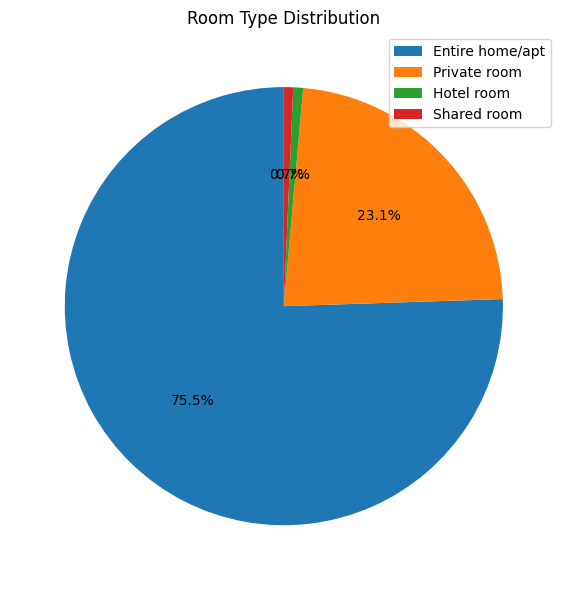

In [ ]:
# Room Type Distribution (Pie Chart)
fig, ax = plt.subplots(figsize=(6, 6))

room_type_counts = listings['room_type'].value_counts()
ax.pie(room_type_counts.values, autopct='%1.1f%%', startangle=90)
ax.set_title('Room Type Distribution')
plt.legend(labels=room_type_counts.index, loc='best')
plt.tight_layout()
plt.show()

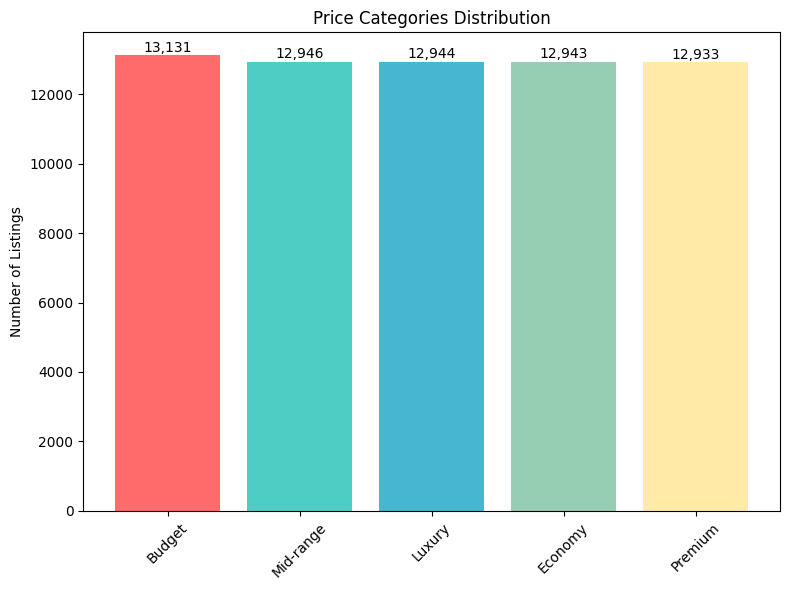

In [ ]:
# Price Categories Distribution
fig, ax = plt.subplots(figsize=(8, 6))

price_cat_counts = listings['price_category'].value_counts()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

bars = ax.bar(price_cat_counts.index, price_cat_counts.values, color=colors)
ax.set_title('Price Categories Distribution')
ax.set_ylabel('Number of Listings')
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 100, f'{int(height):,}', ha='center')

plt.tight_layout()
plt.show()


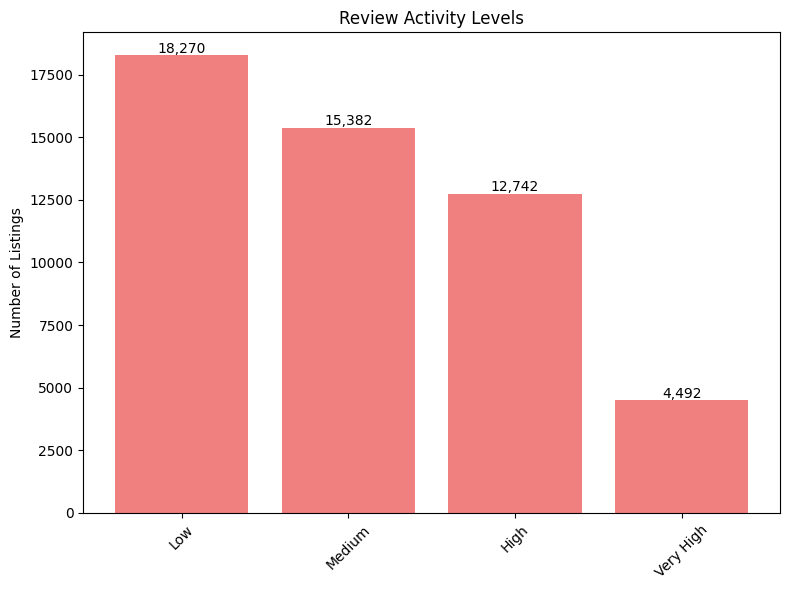

In [ ]:
# Review Activity Levels
fig, ax = plt.subplots(figsize=(8, 6))

review_activity_counts = listings['review_activity'].value_counts()
bars = ax.bar(review_activity_counts.index, review_activity_counts.values, color='lightcoral')
ax.set_title('Review Activity Levels')
ax.set_ylabel('Number of Listings')
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 100, f'{int(height):,}', ha='center')

plt.tight_layout()
plt.show()


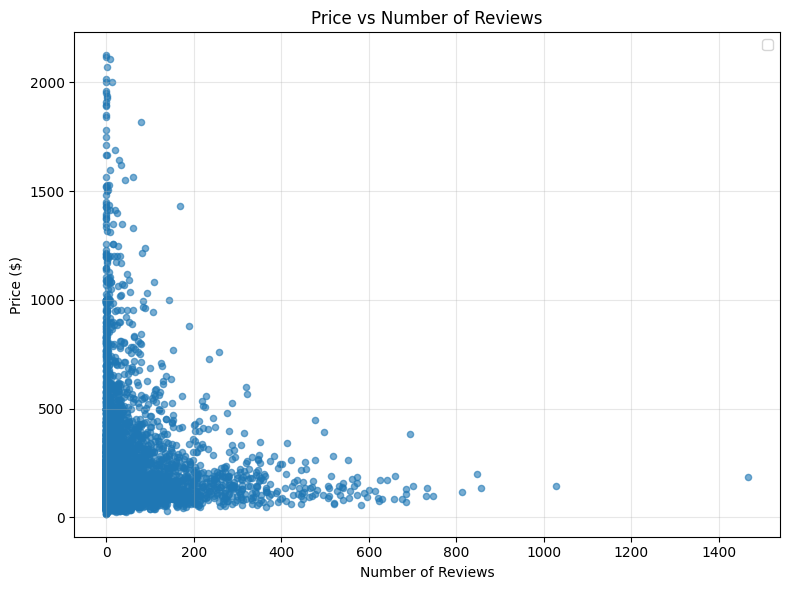

In [ ]:
# Price vs Number of Reviews
fig, ax = plt.subplots(figsize=(8, 6))

sample_data = listings.sample(n=min(5000, len(listings)), random_state=42)
ax.scatter(sample_data['number_of_reviews'], sample_data['price'], alpha=0.6, s=20)
ax.set_title('Price vs Number of Reviews')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Price ($)')
ax.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

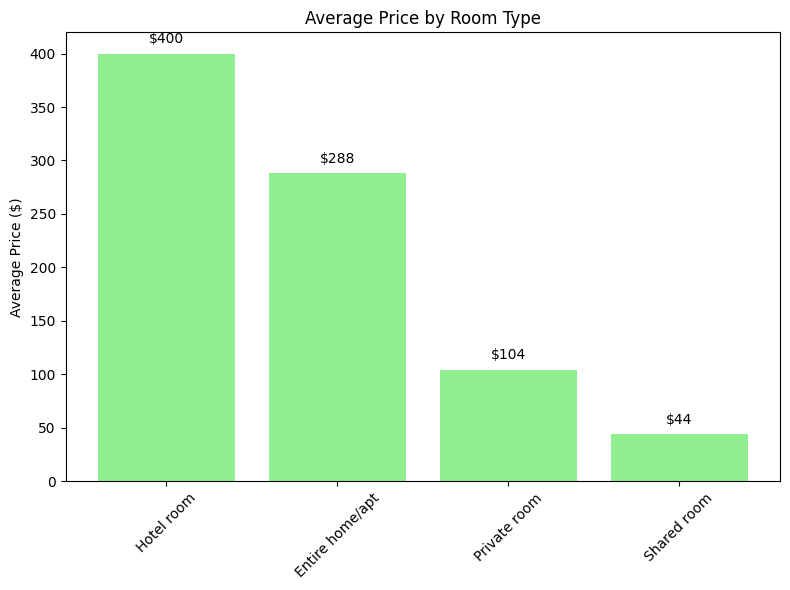

In [ ]:
# Average Price by Room Type
fig, ax = plt.subplots(figsize=(8, 6))

avg_price_by_room = listings.groupby('room_type')['price'].mean().sort_values(ascending=False)
bars = ax.bar(avg_price_by_room.index, avg_price_by_room.values, color='lightgreen')
ax.set_title('Average Price by Room Type')
ax.set_ylabel('Average Price ($)')
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 10, f'${height:.0f}', ha='center')

plt.tight_layout()
plt.show()

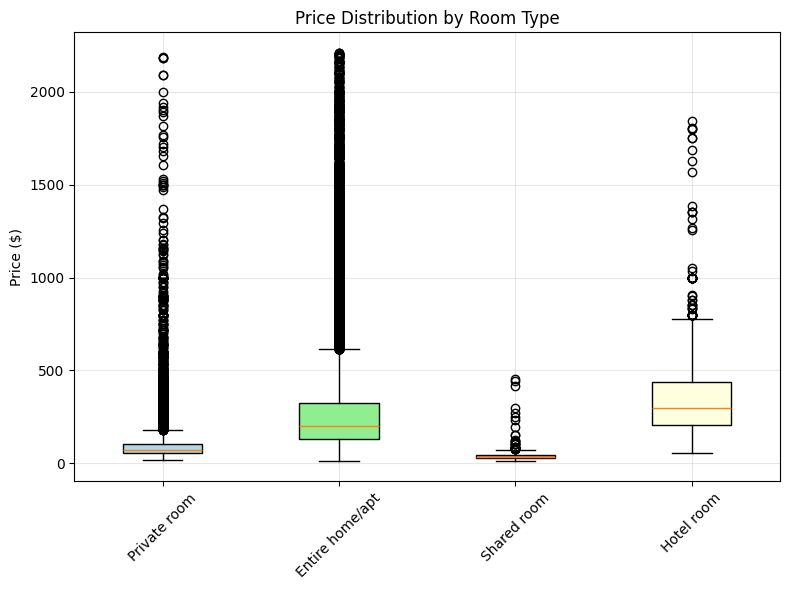

In [ ]:
# Boxplot — Price by Room Type
fig, ax = plt.subplots(figsize=(8, 6))

room_types = listings['room_type'].unique()
price_data = [listings[listings['room_type'] == rt]['price'] for rt in room_types]
colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightyellow']

bp = ax.boxplot(price_data, labels=room_types, patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Price Distribution by Room Type')
ax.set_ylabel('Price ($)')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

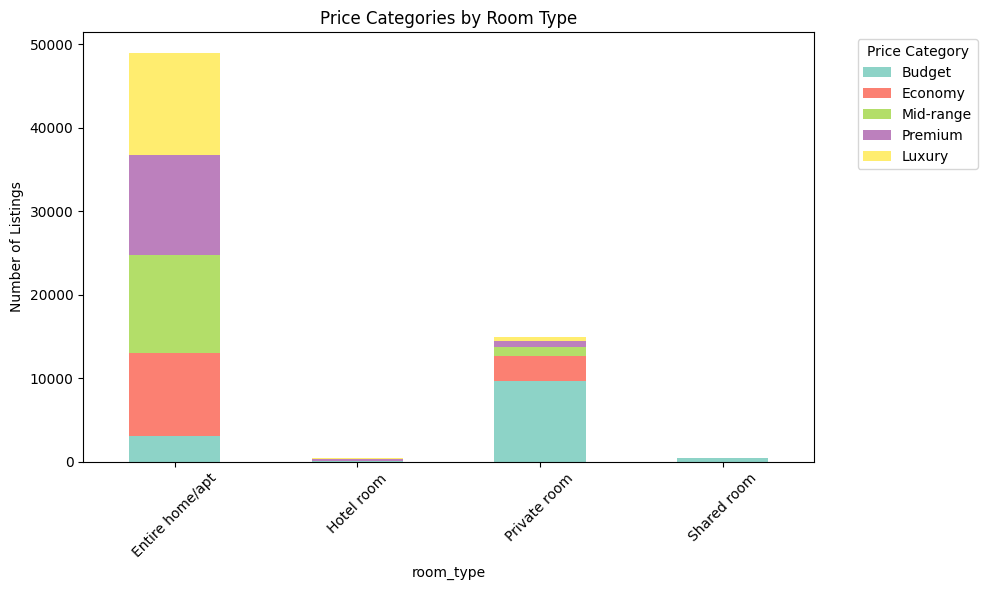

In [ ]:
# Stacked Bar — Price Categories by Room Type
fig, ax = plt.subplots(figsize=(10, 6))

price_room_cross = pd.crosstab(listings['room_type'], listings['price_category'])
price_room_cross.plot(kind='bar', stacked=True, colormap='Set3', ax=ax)

ax.set_title('Price Categories by Room Type')
ax.set_ylabel('Number of Listings')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Price Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

plt.show()

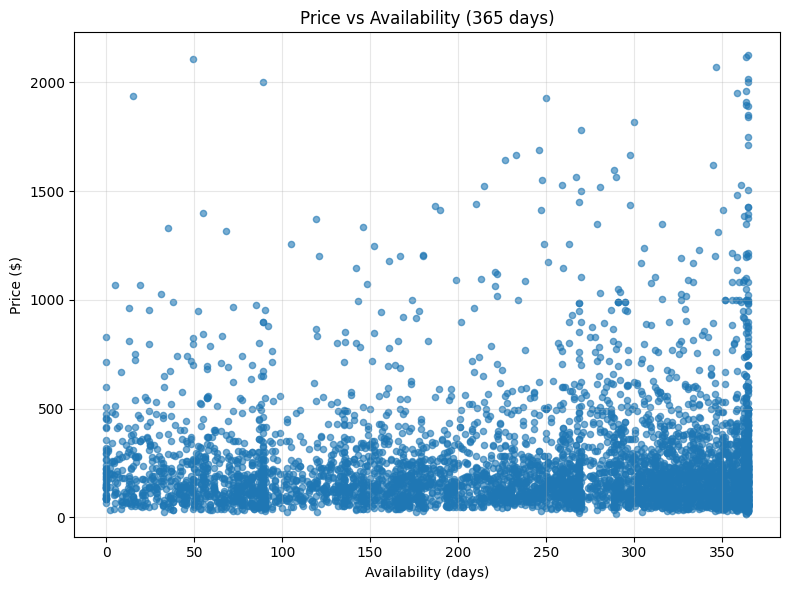

In [ ]:
# Price vs Availability (365 Days)
fig, ax = plt.subplots(figsize=(8, 6))

sample_data = listings.sample(n=min(5000, len(listings)), random_state=42)
ax.scatter(sample_data['availability_365'], sample_data['price'], alpha=0.6, s=20)
ax.set_title('Price vs Availability (365 days)')
ax.set_xlabel('Availability (days)')
ax.set_ylabel('Price ($)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


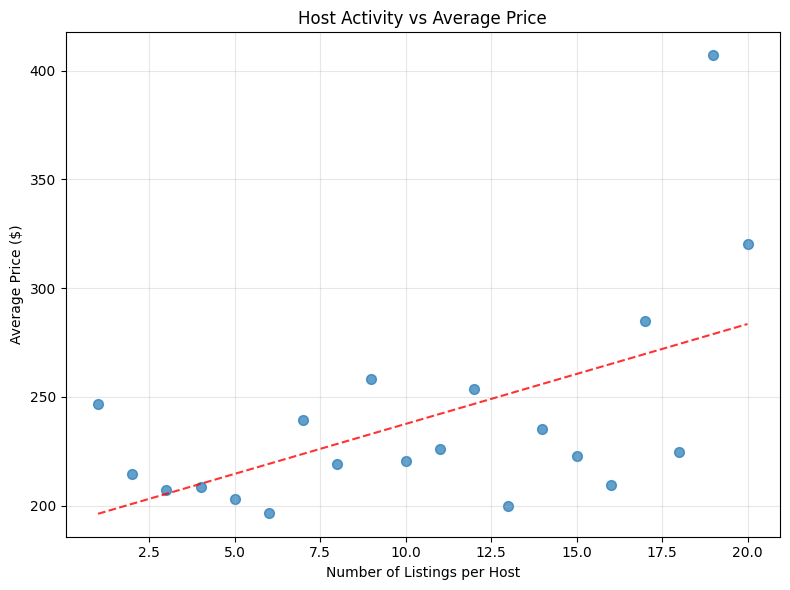

In [ ]:
# Host activity analysis
host_activity = listings.groupby('calculated_host_listings_count')['price'].mean()
host_activity = host_activity[host_activity.index <= 20]  # Limit to reasonable range

plt.figure(figsize=(8, 6))
plt.scatter(host_activity.index, host_activity.values, alpha=0.7, s=50)
plt.xlabel('Number of Listings per Host')
plt.ylabel('Average Price ($)')
plt.title('Host Activity vs Average Price')
plt.grid(True, alpha=0.3)

# Trend line
z = np.polyfit(host_activity.index, host_activity.values, 1)
p = np.poly1d(z)
plt.plot(host_activity.index, p(host_activity.index), "r--", alpha=0.8)

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

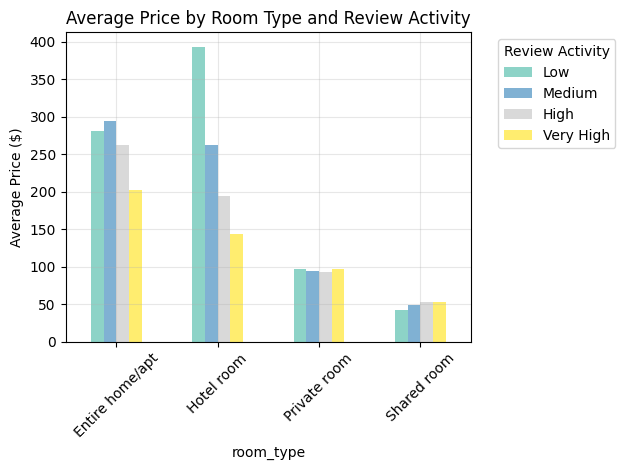

In [ ]:
# Price distribution by room type and review activity
pivot_data = listings.pivot_table(
    values='price',
    index='room_type',
    columns='review_activity',
    aggfunc='mean'
)

plt.figure(figsize=(10, 6))
pivot_data.plot(kind='bar', colormap='Set3')
plt.title('Average Price by Room Type and Review Activity')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Review Activity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

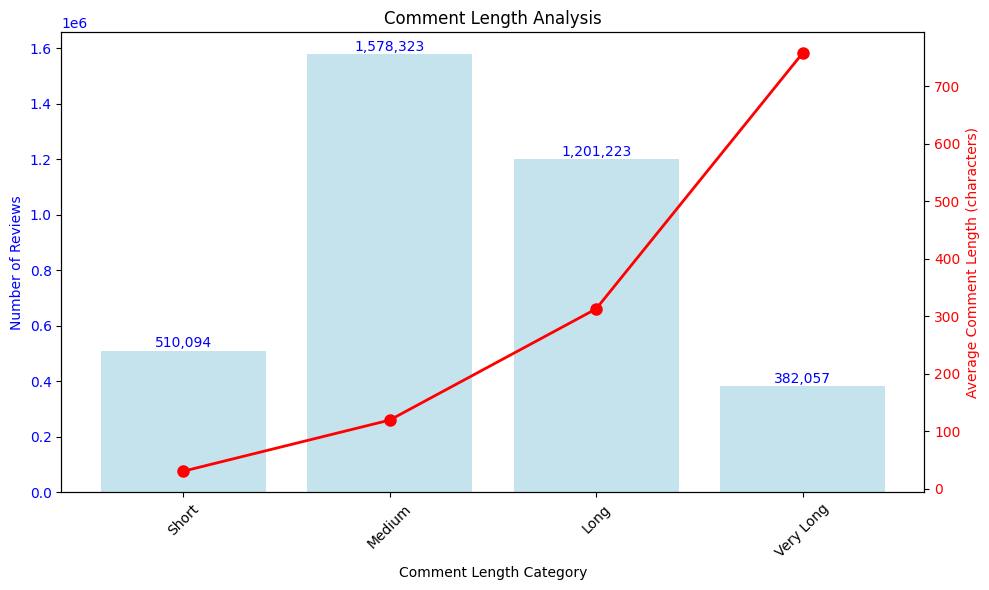

In [ ]:
# Comment length analysis
comment_length_stats = reviews_df1.groupby('comment_category')['comment_length'].agg(['mean', 'count'])

fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

bars = ax1.bar(range(len(comment_length_stats)), comment_length_stats['count'], alpha=0.7, color='lightblue')
ax1.set_xlabel('Comment Length Category')
ax1.set_ylabel('Number of Reviews', color='blue')
ax1.set_title('Comment Length Analysis')
ax1.set_xticks(range(len(comment_length_stats)))
ax1.set_xticklabels(comment_length_stats.index, rotation=45)
ax1.tick_params(axis='y', labelcolor='blue')

line = ax2.plot(range(len(comment_length_stats)), comment_length_stats['mean'], 'ro-', linewidth=2, markersize=8)
ax2.set_ylabel('Average Comment Length (characters)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Add labels
for i, v in enumerate(comment_length_stats['count']):
    ax1.text(i, v + 1000, f'{v:,}', ha='center', va='bottom', color='blue')

plt.tight_layout()
plt.show()


In [ ]:
"""
#  Word Cloud from Cleaned Comments
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Combine all cleaned comments into one string
text_data = ' '.join(reviews_df1['comments_clean'].dropna().astype(str))

# Optional: Add extra stopwords if needed
stopwords = set(STOPWORDS)
stopwords.update(['stay', 'place', 'host', 'apartment', 'really', 'would', 'nice', 'great'])

# Create the word cloud
wordcloud = WordCloud(width=1200, height=600, background_color='white',
                      stopwords=stopwords, colormap='viridis').generate(text_data)

# Display the word cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Guest Reviews', fontsize=20)
plt.show()
"""

"\n#  Word Cloud from Cleaned Comments\nfrom wordcloud import WordCloud, STOPWORDS\nimport matplotlib.pyplot as plt\n\n# Combine all cleaned comments into one string\ntext_data = ' '.join(reviews_df1['comments_clean'].dropna().astype(str))\n\n# Optional: Add extra stopwords if needed\nstopwords = set(STOPWORDS)\nstopwords.update(['stay', 'place', 'host', 'apartment', 'really', 'would', 'nice', 'great'])\n\n# Create the word cloud\nwordcloud = WordCloud(width=1200, height=600, background_color='white',\n                      stopwords=stopwords, colormap='viridis').generate(text_data)\n\n# Display the word cloud\nplt.figure(figsize=(15, 7))\nplt.imshow(wordcloud, interpolation='bilinear')\nplt.axis('off')\nplt.title('Most Common Words in Guest Reviews', fontsize=20)\nplt.show()\n"

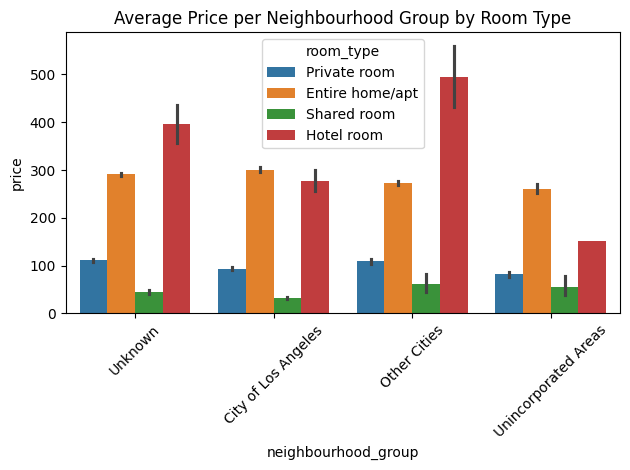

In [ ]:
# 1. Barplot: Average price per neighbourhood group by room type
sns.barplot(data=listings_df1, x="neighbourhood_group", y="price",hue="room_type",estimator="mean")
plt.title("Average Price per Neighbourhood Group by Room Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

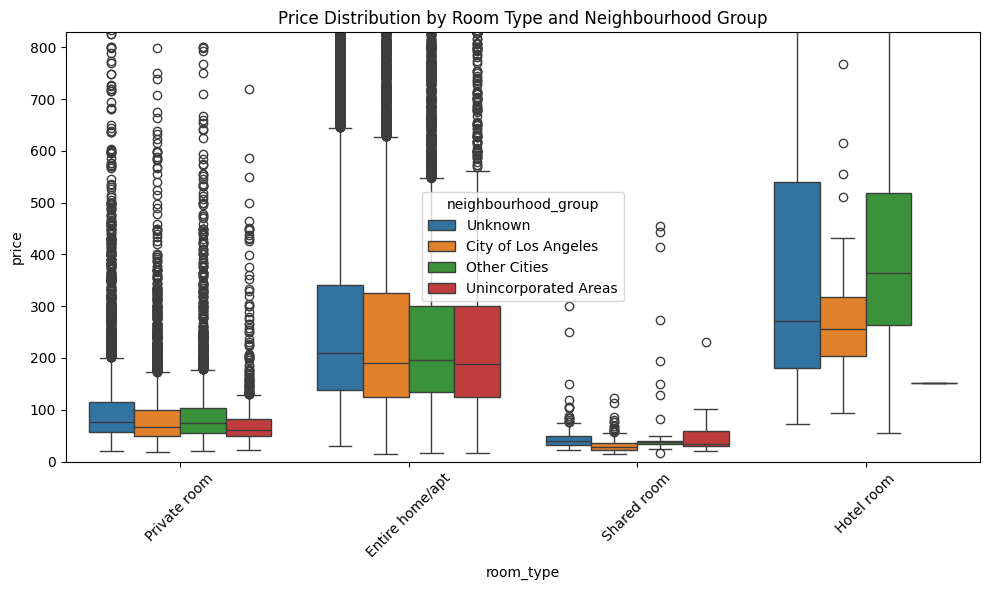

In [ ]:
# Boxplot: Price distribution by room_type & neighbourhood_group
plt.figure(figsize=(10,6))
sns.boxplot(
    data=listings_df1,
    x="room_type",
    y="price",
    hue="neighbourhood_group"
)
plt.title("Price Distribution by Room Type and Neighbourhood Group")
plt.xticks(rotation=45)
plt.ylim(0, listings_df['price'].quantile(0.95))  # limit extreme outliers
plt.tight_layout()
plt.show()

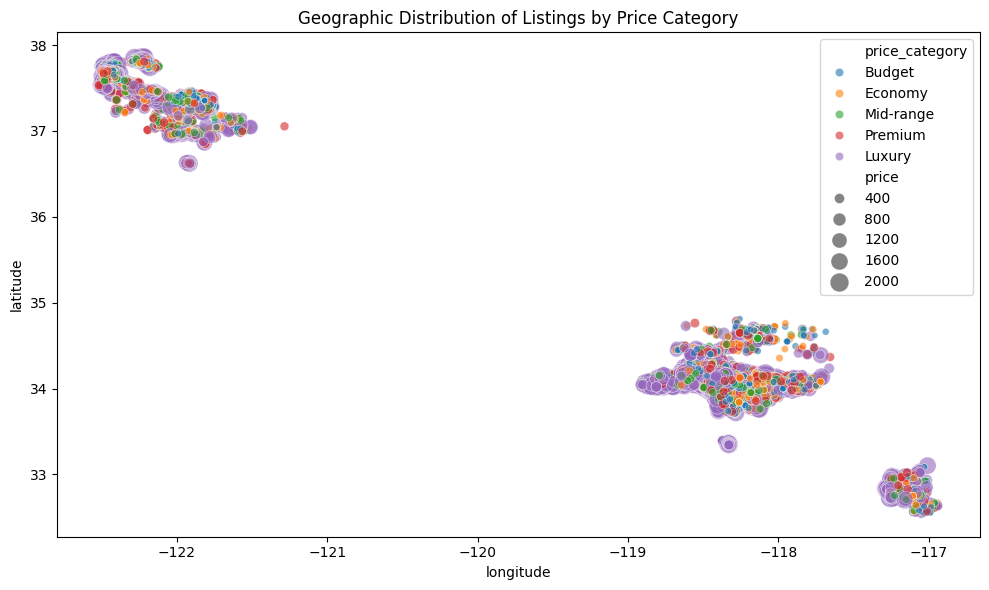

In [ ]:
# Scatterplot: Latitude vs Longitude with price as color & size
plt.figure(figsize=(10,6))
sns.scatterplot(
  data=listings_df1,
  x="longitude",
  y="latitude",
  hue="price_category",
  size="price",
  sizes=(20, 200),
  alpha=0.6
)
plt.title("Geographic Distribution of Listings by Price Category")
plt.tight_layout()
plt.show()

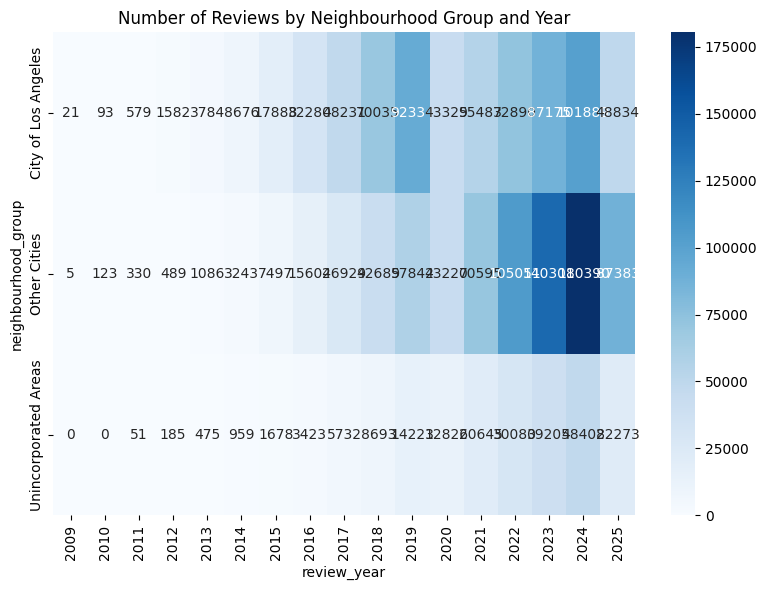

In [ ]:
# Heatmap: Number of reviews per neighbourhood_group & review_year
merged = reviews_df1.merge(
    listings_df[['id', 'neighbourhood_group']],
    left_on="listing_id",
    right_on="id",
    how="left"
)
heatmap_data = merged.groupby(["neighbourhood_group", "review_year"]).size().unstack(fill_value=0)
plt.figure(figsize=(8,6))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")
plt.title("Number of Reviews by Neighbourhood Group and Year")
plt.tight_layout()
plt.show()

In [ ]:
# Bubble Map: Longitude, Latitude, Price, Room Type (Great for spotting expensive clusters)
fig = px.scatter_mapbox(
    listings_df1,
    lat="latitude",
    lon="longitude",
    size="price",
    color="room_type",
    hover_name="name",
    size_max=15,
    zoom=10,
    mapbox_style="carto-positron"
)
fig.show()

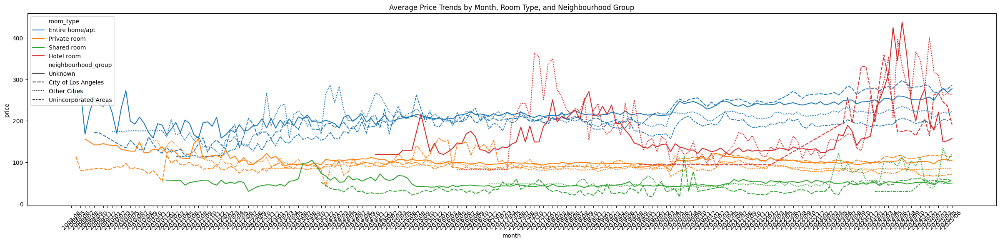

In [ ]:
#  Price Trends Over Time by Room Type & Neighbourhood Group (Tracks seasonal review trends across areas)
merged_price = reviews_df1.merge(
    listings_df1[['id', 'room_type', 'neighbourhood_group', 'price']],
    left_on='listing_id',
    right_on='id'
)
merged_price['date'] = pd.to_datetime(merged_price['date'])
merged_price['month'] = merged_price['date'].dt.to_period('M').astype(str)

avg_price = merged_price.groupby(
    ['month', 'room_type', 'neighbourhood_group']
)['price'].mean().reset_index()

plt.figure(figsize=(30, 6))
sns.lineplot(
    data=avg_price,
    x='month',
    y='price',
    hue='room_type',
    style='neighbourhood_group'
)
plt.xticks(rotation=45)
plt.title("Average Price Trends by Month, Room Type, and Neighbourhood Group")
plt.show()

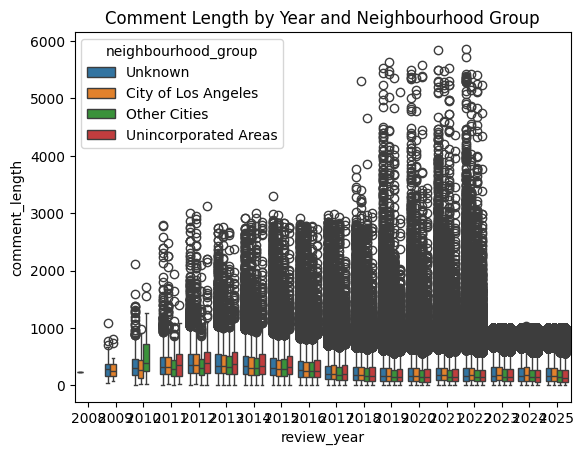

In [ ]:
# Comment Length Distribution Over Years by Neighbourhood Group (Shows if reviews get longer/shorter over the years per area)
merged_comments = reviews_df1.merge(
    listings_df1[['id', 'neighbourhood_group']],
    left_on='listing_id',
    right_on='id'
)
sns.boxplot(
    data=merged_comments,
    x='review_year',
    y='comment_length',
    hue='neighbourhood_group'
)
plt.title("Comment Length by Year and Neighbourhood Group")
plt.show()

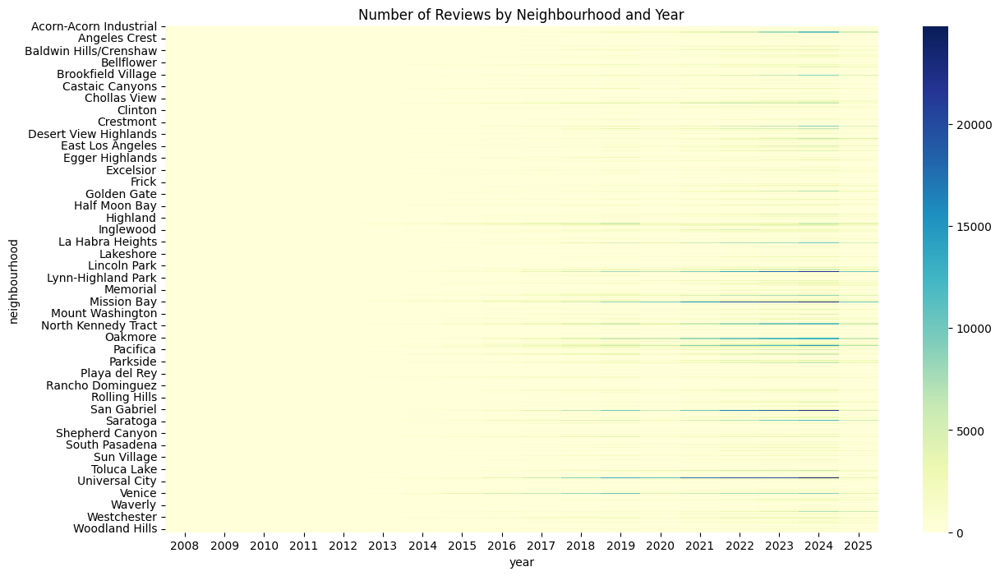

In [ ]:
# Heatmap of Number of Reviews by Neighbourhood & Review Year
merged_heatmap = reviews_df1.merge(
    listings_df1[['id', 'neighbourhood']],
    left_on='listing_id',
    right_on='id'
)
merged_heatmap['date'] = pd.to_datetime(merged_heatmap['date'])
merged_heatmap['year'] = merged_heatmap['date'].dt.year

review_counts = merged_heatmap.groupby(
    ['neighbourhood', 'year']
)['listing_id'].count().unstack(fill_value=0)

plt.figure(figsize=(14, 8))
sns.heatmap(review_counts, cmap="YlGnBu")
plt.title("Number of Reviews by Neighbourhood and Year")
plt.show()

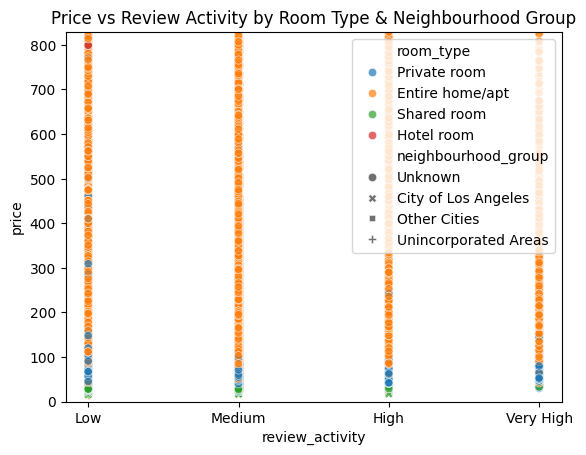

In [ ]:
# Price vs Review Activity by Room Type and Neighbourhood Group (Understand how review frequency (a proxy for popularity) correlates with pricing across different locations and property types.)
#plt.figure(figsize=(12, 6))
sns.scatterplot(data=listings_df1, x='review_activity', y='price',
                hue='room_type', style='neighbourhood_group', alpha=0.7)
plt.title('Price vs Review Activity by Room Type & Neighbourhood Group')
plt.ylim(0, listings_df['price'].quantile(0.95))  # Remove extreme outliers
plt.show()

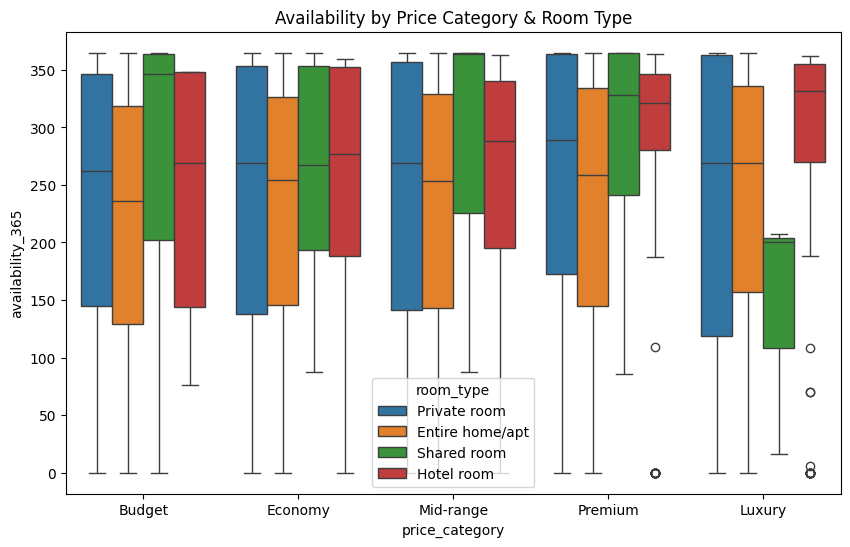

In [ ]:
# Availability Trends Over the Year by Price Category (See if expensive vs budget properties differ in how often they’re available throughout the year.)
plt.figure(figsize=(10, 6))
sns.boxplot(data=listings_df1, x='price_category', y='availability_365', hue='room_type')
plt.title('Availability by Price Category & Room Type')
plt.show()

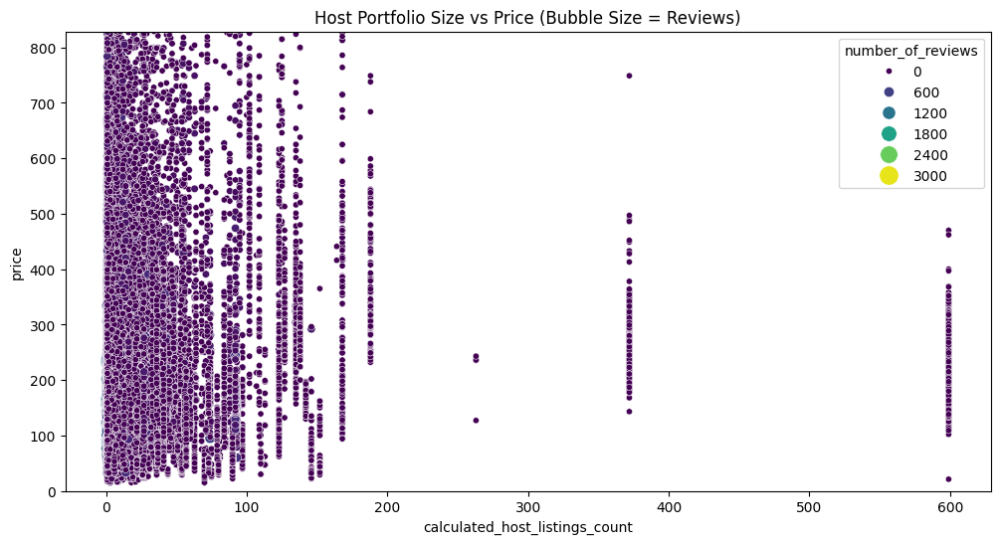

In [ ]:
# Host Size (Number of Listings) vs Price vs Reviews (Discover seasonal or yearly patterns in guest activity.)
plt.figure(figsize=(12, 6))
sns.scatterplot(data=listings_df1, x='calculated_host_listings_count', y='price',
                size='number_of_reviews', hue='number_of_reviews', palette='viridis', sizes=(20, 200))
plt.title('Host Portfolio Size vs Price (Bubble Size = Reviews)')
plt.ylim(0, listings_df['price'].quantile(0.95))
plt.show()

In [ ]:
# Reviews Per Month Trends Over Time by Neighbourhood Group (Visually identify expensive pockets vs affordable areas.)
reviews_merged = reviews_df.merge(listings_df1, left_on='listing_id', right_on='id', how='left')
reviews_merged['date'] = pd.to_datetime(reviews_merged['date'], errors='coerce')
monthly_reviews = reviews_merged.groupby([pd.Grouper(key='date', freq='M'), 'neighbourhood_group'])['reviews_per_month'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_reviews, x='date', y='reviews_per_month', hue='neighbourhood_group')
plt.title('Average Reviews Per Month Over Time by Neighbourhood Group')
plt.show()

NameError: name 'reviews_df' is not defined

In [ ]:
# Geographic Price Clustering (Scatter Map)
plt.figure(figsize=(10, 8))
sns.scatterplot(data=listings_df1, x='longitude', y='latitude',
                hue='price_normalized', palette='coolwarm', alpha=0.6, s=30)
plt.title('Geographic Price Distribution')
plt.show()

In [ ]:
# License Compliance by Price Category and Neighbourhood Group (Check if high-end areas have more licensed listings (important for regulatory insights)
license_data = listings_df.groupby(['neighbourhood_group', 'price_category', 'license']).size().reset_index(name='count')
plt.figure(figsize=(12, 6))
sns.barplot(data=license_data, x='neighbourhood_group', y='count',
            hue='license', palette='Set2')
plt.title('License Compliance by Price Category & Location')
plt.show()

NameError: name 'listings_df1' is not defined

In [ ]:
# Facet grid: Price distribution by neighbourhood group
g = sns.FacetGrid(listings_df1, col='neighbourhood_group', height=6, aspect=1)
g.map_dataframe(sns.scatterplot, x='longitude', y='latitude', hue='price_category', alpha=0.6)
g.add_legend()
plt.subplots_adjust(top=0.85)
g.fig.suptitle("Listings Locations Colored by Price Category Across Neighbourhood Groups")
plt.show()

In [ ]:
# Hexbin plot: Density of listings by location
plt.figure(figsize=(10, 8))
plt.hexbin(
    listings_df1['longitude'],
    listings_df1['latitude'],
    gridsize=50,
    cmap='plasma',
    bins='log'
)
plt.colorbar(label='Log(Number of Listings)')
plt.title("Density of Listings by Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [ ]:
# Scatter plot: Price vs location
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=listings_df1,
    x='longitude',
    y='latitude',
    hue='price_normalized',
    palette='coolwarm',
    size='availability_365',
    sizes=(20, 200),
    alpha=0.6
)
plt.title("Listings by Location: Price Normalized & Availability")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label='Price Normalized')  # optional for reference
plt.tight_layout()
plt.show()

In [ ]:
# Scatter plot: Listings colored by price category
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=listings_df1,
    x='longitude',
    y='latitude',
    hue='price_category',
    size='number_of_reviews',
    sizes=(20, 200),
    alpha=0.6,
    palette='viridis'
)
plt.title("Listings by Location: Price Category & Number of Reviews")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
!pip install joypy
from joypy import joyplot

In [ ]:
# Ridgeline Plot of Price Distribution by Room Type and Neighbourhood Group
# Purpose: Show the full distribution of prices across room types and areas in a single plot.plt.figure(figsize=(12,8))
joyplot(
    data=listings_df1,
    by='room_type',
    column='price',
    overlap=0.5,
    colormap=plt.cm.viridis,
    kind='kde'
)
plt.title("Price Distribution Ridgeline by Room Type")
plt.show()

In [ ]:
# Sunburst Plot: Neighbourhood → Room Type → Price Category

# Purpose: Hierarchical breakdown of listings, showing proportions in each category.

fig = px.sunburst(
    listings_df1,
    path=['neighbourhood_group', 'room_type', 'price_category'],
    values='id',
    color='price_normalized',
    color_continuous_scale='RdBu',
    title="Sunburst of Listings: Neighbourhood → Room Type → Price Category"
)
fig.show()

In [ ]:
# Network Graph of Hosts and Neighbourhoods

# Purpose: Show connections between hosts and neighbourhoods to visualize concentration of listings.
import networkx as nx

G = nx.from_pandas_edgelist(
    listings_df1[['host_name', 'neighbourhood_group']].dropna(),
    source='host_name',
    target='neighbourhood_group'
)
plt.figure(figsize=(12,12))
nx.draw(G, with_labels=True, node_size=50, node_color='skyblue', edge_color='gray', alpha=0.6)
plt.title("Network of Hosts and Neighbourhood Groups")
plt.show()

### Visualizations based on question

Revenue Potential Analysis

In [ ]:
# Revenue potential metrics
revenue_metrics = listings.groupby('neighbourhood').agg({
    'price': ['mean', 'median', 'count'],
    'number_of_reviews': 'mean',
    'reviews_per_month': 'mean',
    'availability_365': 'mean'
}).round(2)

revenue_metrics.columns = [
    'avg_price', 'median_price', 'listing_count',
    'avg_reviews', 'avg_reviews_per_month', 'avg_availability'
]

# Monthly revenue estimate and occupancy rate
revenue_metrics['estimated_monthly_revenue'] = (
    revenue_metrics['avg_price'] *
    revenue_metrics['avg_reviews_per_month'] *
    (365 - revenue_metrics['avg_availability']) / 365
)
revenue_metrics['occupancy_rate'] = (365 - revenue_metrics['avg_availability']) / 365 * 100

revenue_metrics.head()


,avg_price,median_price,listing_count,avg_reviews,avg_reviews_per_month,avg_availability,estimated_monthly_revenue,occupancy_rate
neighbourhood,,,,,,,,
Acorn-Acorn Industrial,126.00,95.0,5,13.40,1.36,218.20,68.919584,40.219178
Acton,306.58,130.5,12,10.92,0.68,250.25,65.540924,31.438356
Adams Point,137.83,119.5,36,61.33,1.20,212.31,69.189905,41.832877
Adams-Normandie,84.33,58.5,60,19.38,0.94,260.50,22.695167,28.630137
Agoura Hills,353.65,299.0,46,23.91,0.68,248.65,76.657755,31.876712


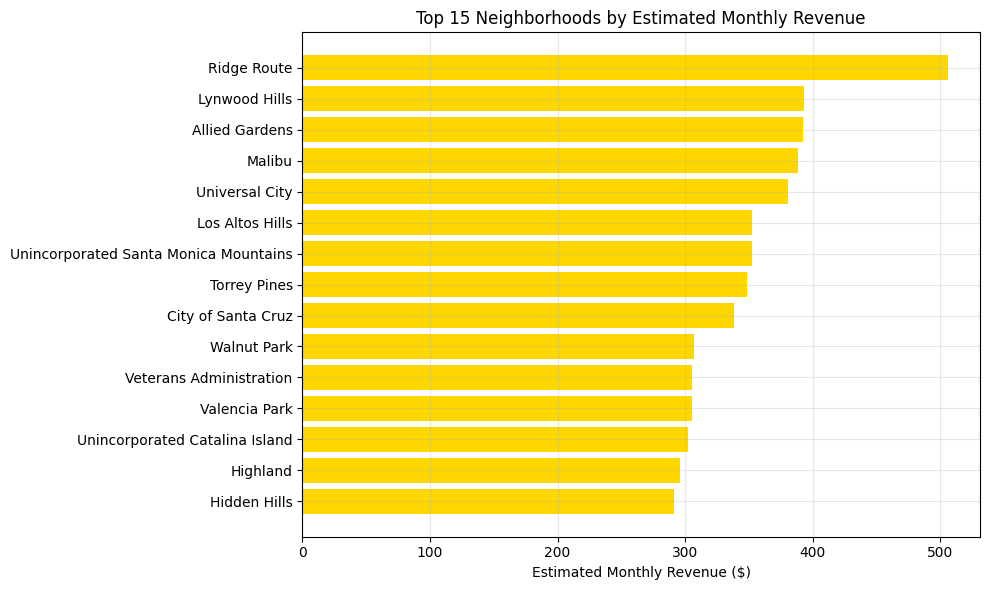

In [ ]:
# Top 15 Neighborhoods by Monthly Revenue
top_revenue = revenue_metrics.nlargest(15, 'estimated_monthly_revenue')

plt.figure(figsize=(10, 6))
plt.barh(top_revenue.index, top_revenue['estimated_monthly_revenue'], color='gold')
plt.xlabel('Estimated Monthly Revenue ($)')
plt.title('Top 15 Neighborhoods by Estimated Monthly Revenue')
plt.grid(True, alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

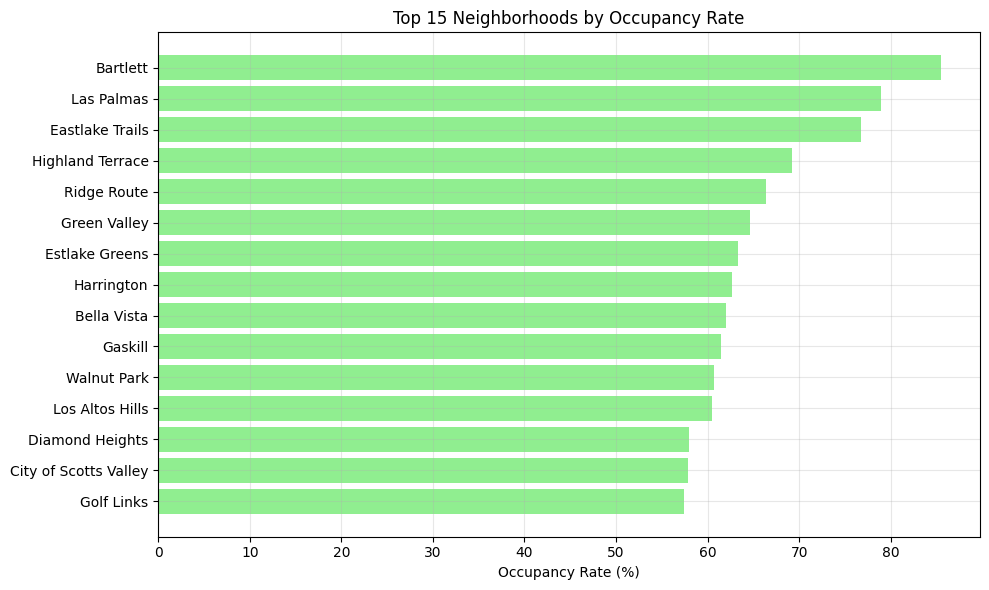

In [ ]:
# Top 15 Neighborhoods by Occupancy
top_occupancy = revenue_metrics.nlargest(15, 'occupancy_rate')

plt.figure(figsize=(10, 6))
plt.barh(top_occupancy.index, top_occupancy['occupancy_rate'], color='lightgreen')
plt.xlabel('Occupancy Rate (%)')
plt.title('Top 15 Neighborhoods by Occupancy Rate')
plt.grid(True, alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


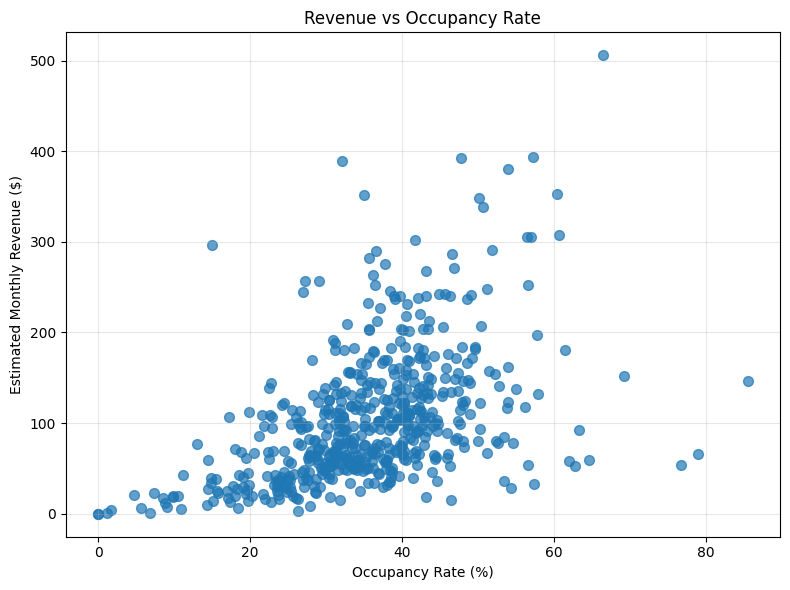

In [ ]:
# Revenue vs Occupancy Rate Scatter

plt.figure(figsize=(8, 6))
plt.scatter(revenue_metrics['occupancy_rate'], revenue_metrics['estimated_monthly_revenue'], alpha=0.7, s=50)
plt.xlabel('Occupancy Rate (%)')
plt.ylabel('Estimated Monthly Revenue ($)')
plt.title('Revenue vs Occupancy Rate')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

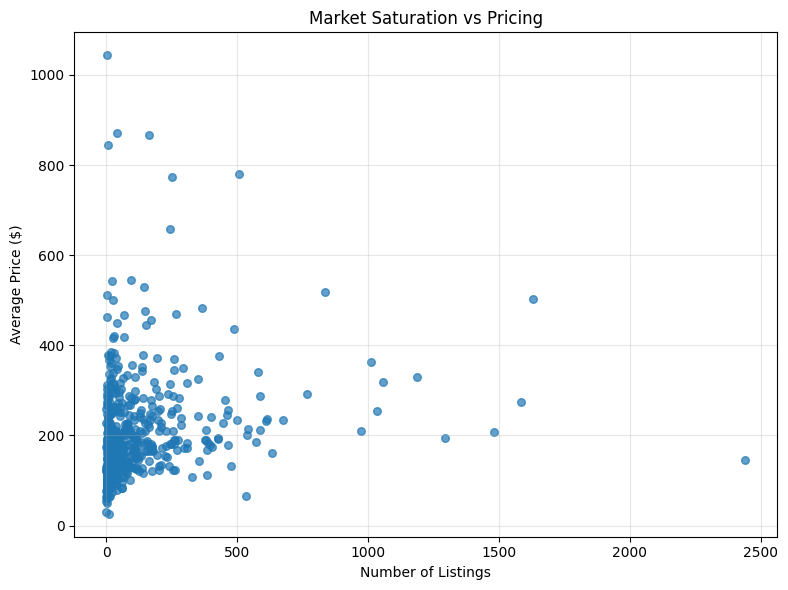

In [ ]:
# Market Saturation vs Pricing
plt.figure(figsize=(8, 6))
plt.scatter(revenue_metrics['listing_count'], revenue_metrics['avg_price'], alpha=0.7, s=30)
plt.xlabel('Number of Listings')
plt.ylabel('Average Price ($)')
plt.title('Market Saturation vs Pricing')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Price variation by competition level
# Group by neighbourhood to calculate price mean and std deviation
price_variation = listings.groupby('neighbourhood')['price'].agg(['mean', 'std']).round(2)

# Count listings per neighbourhood
price_variation['listing_count'] = listings.groupby('neighbourhood').size()

# Define competition levels
price_variation['competition_level'] = pd.cut(
    price_variation['listing_count'],
    bins=[0, 50, 200, 500, float('inf')],
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Group by competition level and calculate average statistics
price_variation_by_competition = price_variation.groupby('competition_level').mean()
price_variation_by_competition


,mean,std,listing_count
competition_level,,,
Low,182.789875,136.381748,18.498433
Medium,218.292657,185.369161,109.412587
High,238.720746,198.581940,306.895522
Very High,279.882400,233.656000,911.520000


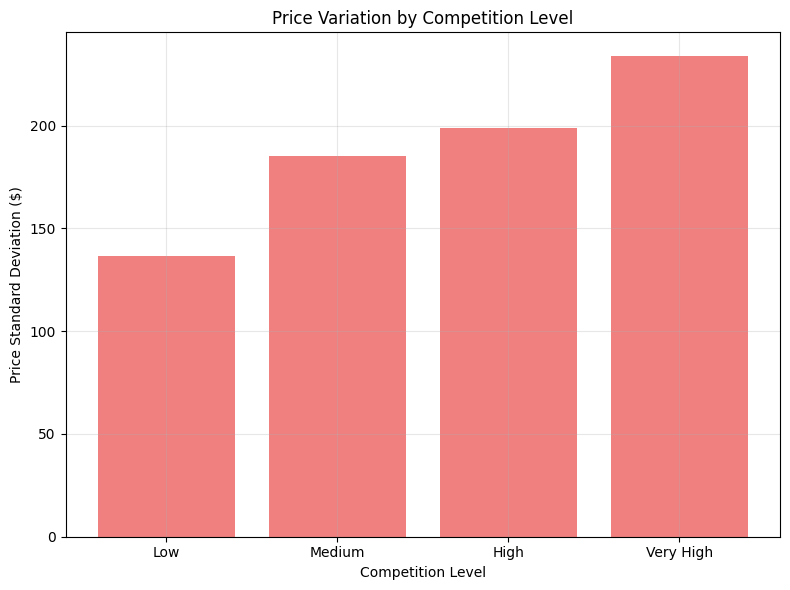

In [ ]:
# Price variation by competition level
# Bar plot for price standard deviation by competition level
plt.figure(figsize=(8, 6))
plt.bar(price_variation_by_competition.index, price_variation_by_competition['std'], color='lightcoral')
plt.xlabel('Competition Level')
plt.ylabel('Price Standard Deviation ($)')
plt.title('Price Variation by Competition Level')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

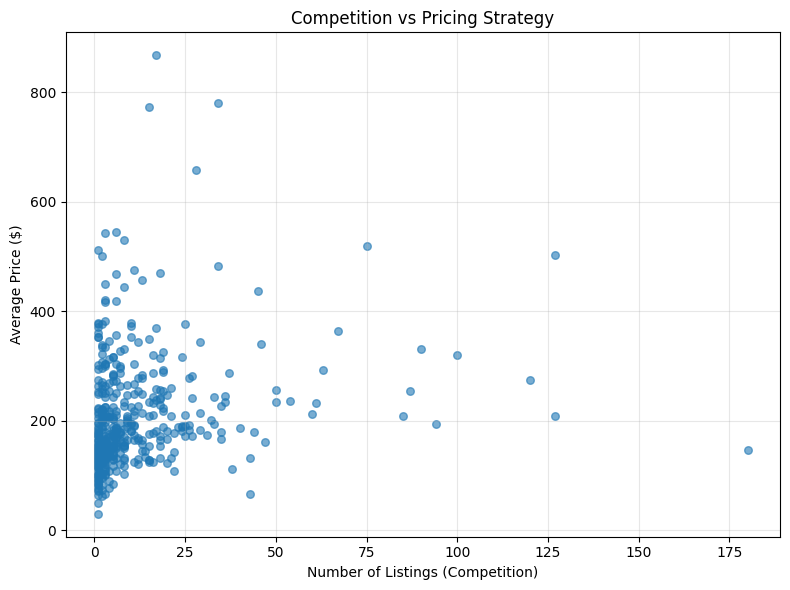

In [ ]:
# Group by neighbourhood: average price and average number of reviews
neighborhood_performance = listings.groupby('neighbourhood').agg({
    'price': 'mean',
    'number_of_reviews': 'mean'
}).round(2)

# Add listing count to the neighborhood performance DataFrame
neighborhood_performance['listing_count'] = sample_data.groupby('neighbourhood').size()
neighborhood_performance.head()

# Scatter plot: competition vs pricing strategy
plt.figure(figsize=(8, 6))
plt.scatter(
    neighborhood_performance['listing_count'],
    neighborhood_performance['price'],
    alpha=0.6,
    s=30
)
plt.xlabel('Number of Listings (Competition)')
plt.ylabel('Average Price ($)')
plt.title('Competition vs Pricing Strategy')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


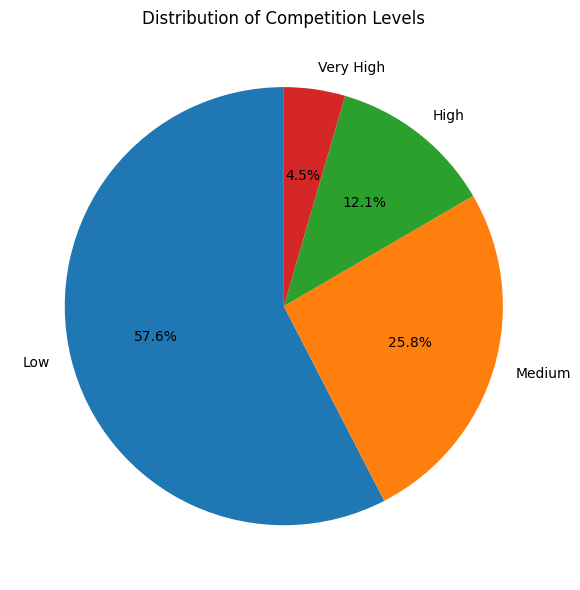

In [ ]:
# Count the number of neighborhoods in each competition level
competition_dist = price_variation['competition_level'].value_counts().sort_index()
competition_dist

# Pie chart showing the distribution of competition levels
plt.figure(figsize=(6, 6))
plt.pie(
    competition_dist.values,
    labels=competition_dist.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Competition Levels')
plt.tight_layout()
plt.show()

#### PROPERTY TYPE PROFITABILITY ANALYSIS

In [ ]:
# Profitability metrics by room type
profitability_metrics = listings_df1.groupby('room_type').agg({
    'price': ['mean', 'median', 'std'],
    'number_of_reviews': 'mean',
    'reviews_per_month': 'mean',
    'availability_365': 'mean'
}).round(2)

# Rename columns for clarity
profitability_metrics.columns = [
    'avg_price', 'median_price', 'price_std',
    'avg_reviews', 'avg_reviews_per_month', 'avg_availability'
]

# Calculate estimated monthly revenue
profitability_metrics['estimated_monthly_revenue'] = (
    profitability_metrics['avg_price'] *
    profitability_metrics['avg_reviews_per_month'] *
    (365 - profitability_metrics['avg_availability']) / 365
)

# Calculate occupancy rate
profitability_metrics['occupancy_rate'] = (
    (365 - profitability_metrics['avg_availability']) / 365 * 100
)

profitability_metrics


,avg_price,median_price,price_std,avg_reviews,avg_reviews_per_month,avg_availability,estimated_monthly_revenue,occupancy_rate
room_type,,,,,,,,
Entire home/apt,288.07,200.0,272.94,54.39,1.54,232.17,161.444057,36.391781
Hotel room,399.90,300.0,313.44,15.45,1.06,276.68,102.570734,24.197260
Private room,104.25,72.0,125.04,45.48,1.25,237.40,45.555822,34.958904
Shared room,43.69,34.0,43.84,31.63,1.25,283.19,12.240681,22.413699


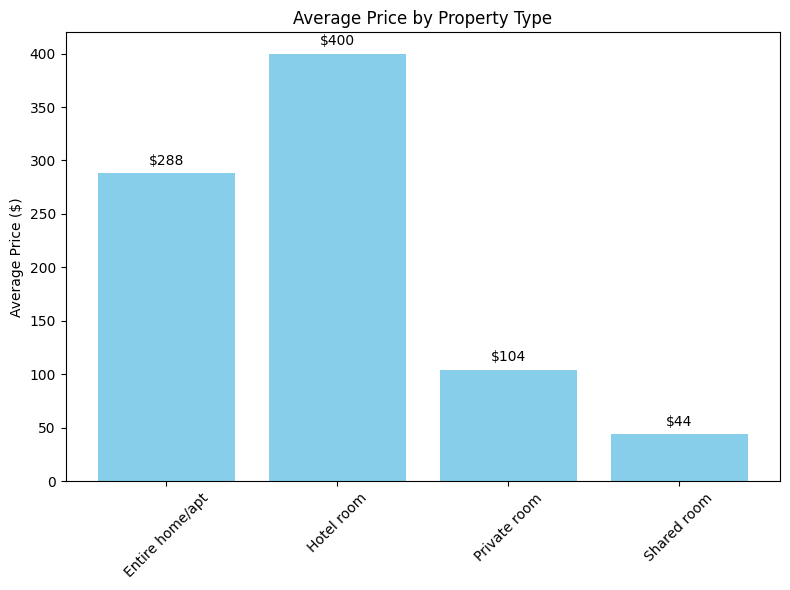

In [ ]:
# Bar plot for average price by property type
plt.figure(figsize=(8, 6))
bars = plt.bar(profitability_metrics.index, profitability_metrics['avg_price'], color='skyblue')
plt.title('Average Price by Property Type')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=45)

# Add value labels
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f"${yval:.0f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()


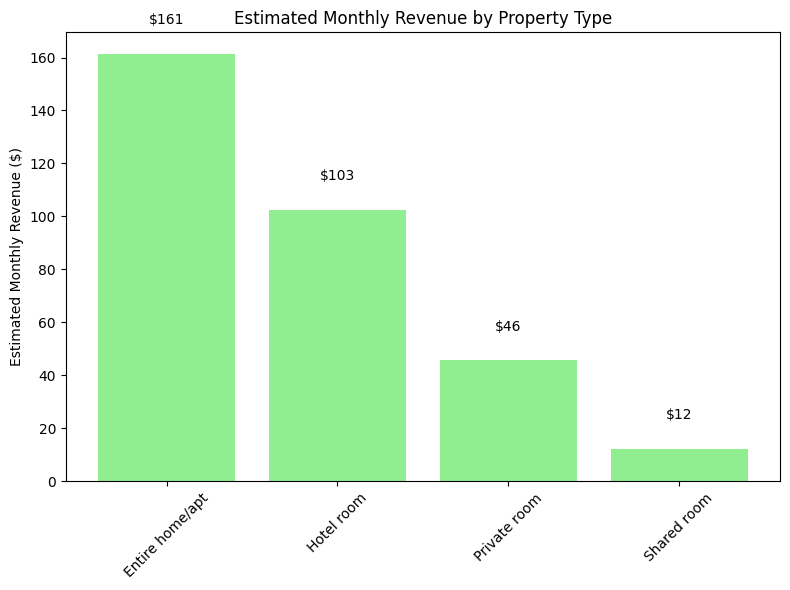

In [ ]:
# Bar plot for estimated monthly revenue by property type
plt.figure(figsize=(8, 6))
bars = plt.bar(profitability_metrics.index, profitability_metrics['estimated_monthly_revenue'], color='lightgreen')
plt.title('Estimated Monthly Revenue by Property Type')
plt.ylabel('Estimated Monthly Revenue ($)')
plt.xticks(rotation=45)

# Add value labels
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, f"${yval:.0f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()


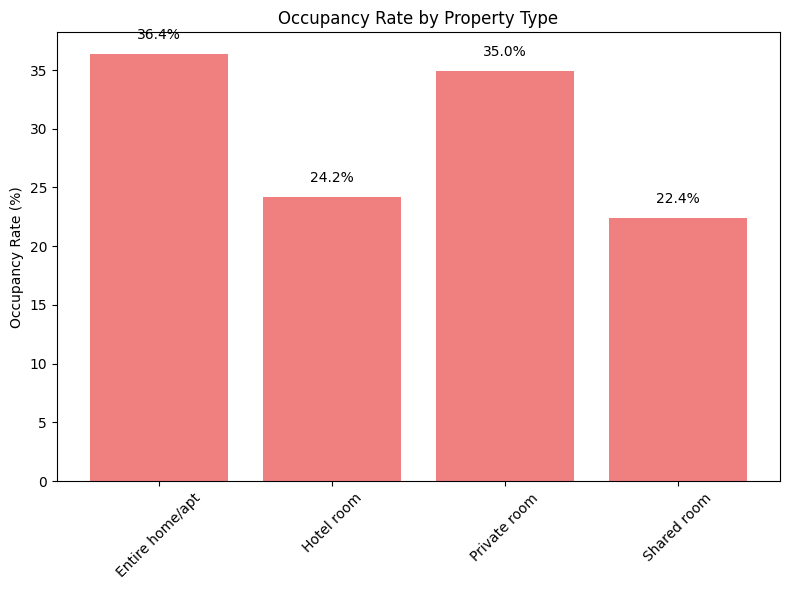

In [ ]:
# Bar plot for occupancy rate by property type
plt.figure(figsize=(8, 6))
bars = plt.bar(profitability_metrics.index, profitability_metrics['occupancy_rate'], color='lightcoral')
plt.title('Occupancy Rate by Property Type')
plt.ylabel('Occupancy Rate (%)')
plt.xticks(rotation=45)

# Add value labels
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', va='bottom')

plt.tight_layout()
plt.show()


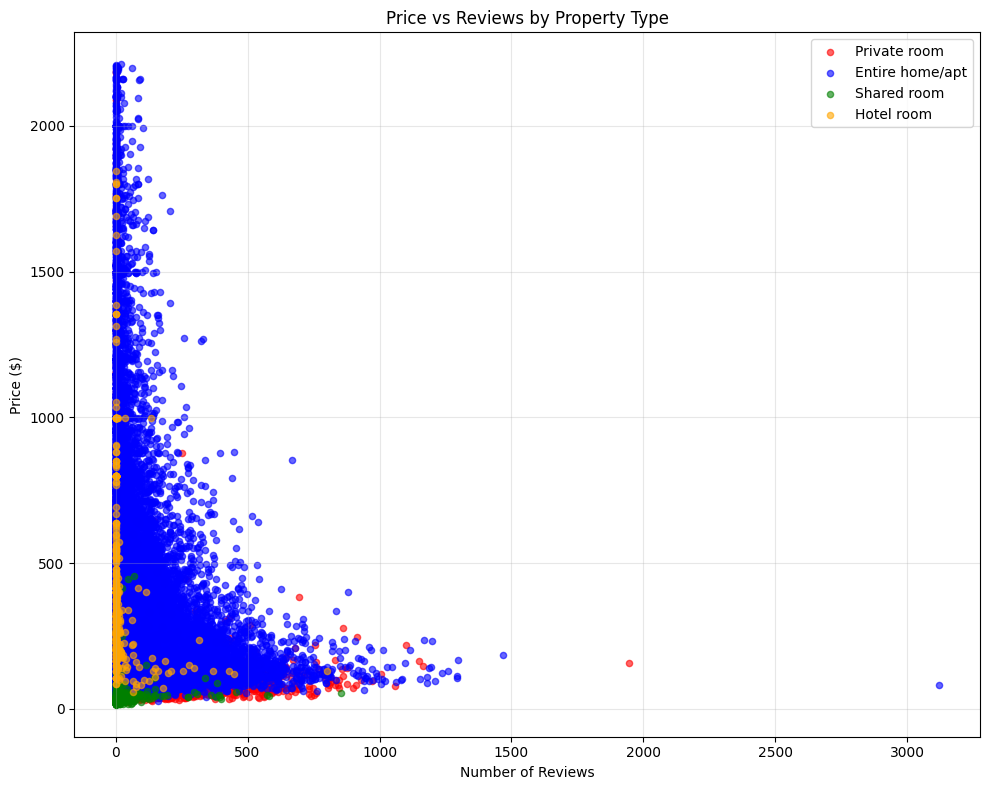

In [ ]:
# Scatter plot of price vs number of reviews by room type
plt.figure(figsize=(10, 8))

room_types = listings_df1['room_type'].unique()
colors = ['red', 'blue', 'green', 'orange']

for i, room_type in enumerate(room_types):
    room_data = listings_df1[listings_df1['room_type'] == room_type]
    plt.scatter(room_data['number_of_reviews'], room_data['price'],
                alpha=0.6, s=20, label=room_type, color=colors[i % len(colors)])

plt.xlabel('Number of Reviews')
plt.ylabel('Price ($)')
plt.title('Price vs Reviews by Property Type')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Pricing Strategy

In [ ]:
# Calculate performance metrics by price category
pricing_performance = listings.groupby('price_category').agg({
    'number_of_reviews': 'mean',
    'reviews_per_month': 'mean',
    'availability_365': 'mean',
    'id': 'count'
}).round(2)

pricing_performance.columns = ['avg_reviews', 'avg_reviews_per_month', 'avg_availability', 'listing_count']
pricing_performance['occupancy_rate'] = (365 - pricing_performance['avg_availability']) / 365 * 100
pricing_performance

,avg_reviews,avg_reviews_per_month,avg_availability,listing_count,occupancy_rate
price_category,,,,,
Budget,43.25,1.17,233.00,13131,36.164384
Economy,67.66,1.59,231.95,12943,36.452055
Mid-range,63.26,1.72,230.72,12946,36.789041
Premium,49.34,1.58,234.06,12933,35.873973
Luxury,36.08,1.28,240.53,12944,34.101370


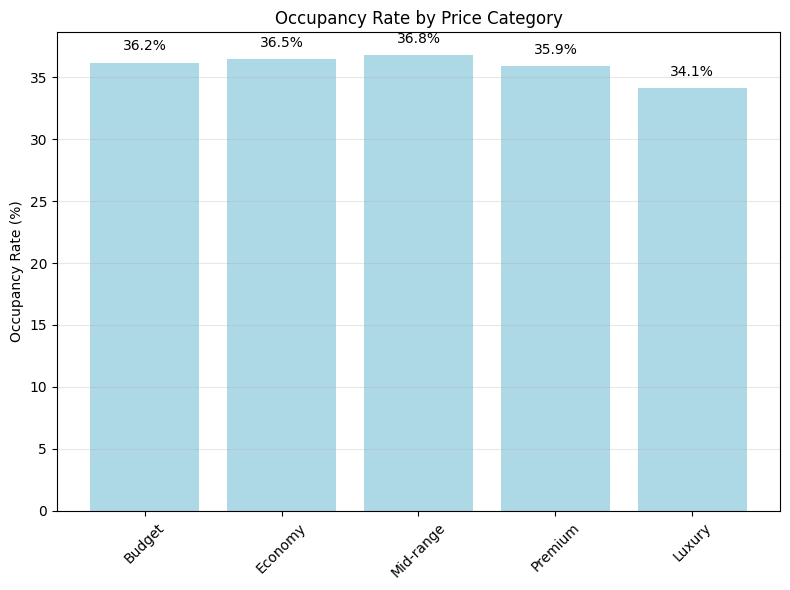

In [ ]:
# Occupancy Rate by Price Category
plt.figure(figsize=(8, 6))
plt.bar(pricing_performance.index, pricing_performance['occupancy_rate'], color='lightblue')
plt.title('Occupancy Rate by Price Category')
plt.ylabel('Occupancy Rate (%)')
plt.xticks(rotation=45)
for i, v in enumerate(pricing_performance['occupancy_rate']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


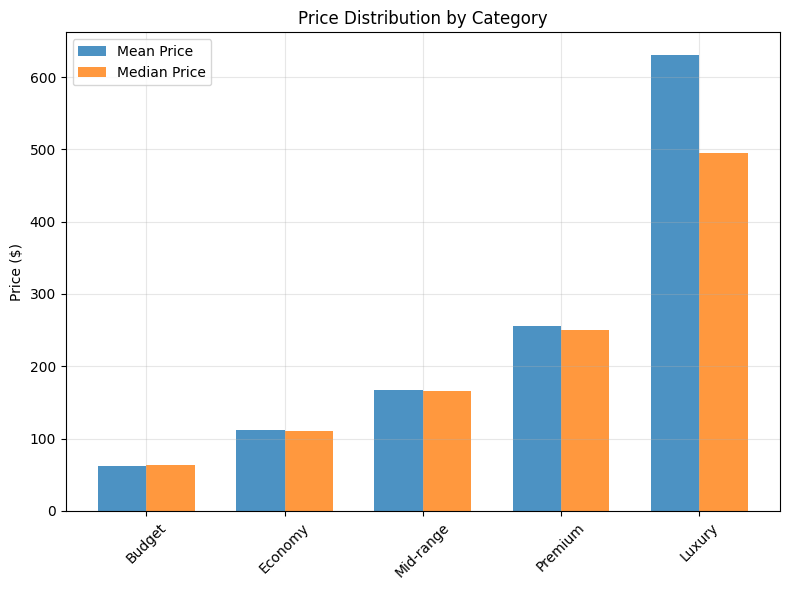

In [ ]:
# Price Distribution by Category
price_ranges = listings.groupby('price_category')['price'].agg(['mean', 'median', 'std']).round(2)

x = range(len(price_ranges))
width = 0.35

plt.figure(figsize=(8, 6))
plt.bar([i - width/2 for i in x], price_ranges['mean'], width, label='Mean Price', alpha=0.8)
plt.bar([i + width/2 for i in x], price_ranges['median'], width, label='Median Price', alpha=0.8)
plt.xticks(ticks=x, labels=price_ranges.index, rotation=45)
plt.title('Price Distribution by Category')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


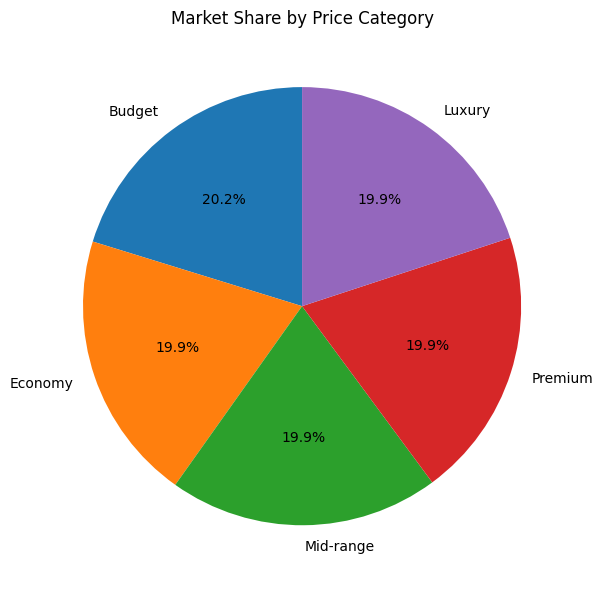

In [ ]:
# Market Share by Price Category
market_share = pricing_performance['listing_count'] / pricing_performance['listing_count'].sum() * 100

plt.figure(figsize=(8, 6))
plt.pie(market_share.values, labels=market_share.index, autopct='%1.1f%%', startangle=90)
plt.title('Market Share by Price Category')
plt.tight_layout()
plt.show()

#### Host Performance

In [ ]:
# Group by host_name and compute metrics
host_metrics = listings_df1.groupby('host_name').agg({
    'id': 'count',
    'price': 'mean',
    'number_of_reviews': 'sum',
    'reviews_per_month': 'mean',
    'availability_365': 'mean'
}).round(2)

host_metrics.columns = ['listing_count', 'avg_price', 'total_reviews', 'avg_reviews_per_month', 'avg_availability']
host_metrics['occupancy_rate'] = (365 - host_metrics['avg_availability']) / 365 * 100

# Categorize hosts by portfolio size
host_metrics['portfolio_size'] = pd.cut(
    host_metrics['listing_count'],
    bins=[0, 1, 5, 20, float('inf')],
    labels=['Single', 'Small', 'Medium', 'Large']
)

host_metrics.head()

,listing_count,avg_price,total_reviews,avg_reviews_per_month,avg_availability,occupancy_rate,portfolio_size
host_name,,,,,,,
(Annie) Yan,2,64.5,125,0.86,41.00,88.767123,Small
1906 Mission,3,118.0,202,1.06,340.33,6.758904,Small
8 West,1,201.0,289,2.85,105.00,71.232877,Single
888 Luxury,22,125.5,475,0.41,301.59,17.372603,Large
A,6,111.5,25,1.13,250.33,31.416438,Medium


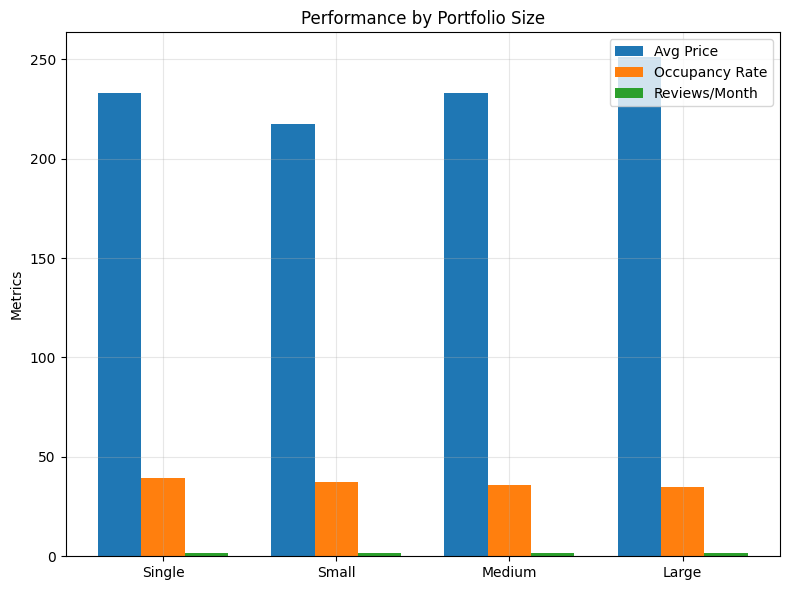

In [ ]:
# Performance by Portfolio Size
portfolio_performance = host_metrics.groupby('portfolio_size').agg({
    'avg_price': 'mean',
    'occupancy_rate': 'mean',
    'avg_reviews_per_month': 'mean'
}).round(2)

x = range(len(portfolio_performance))
width = 0.25

plt.figure(figsize=(8, 6))
plt.bar([i - width for i in x], portfolio_performance['avg_price'], width, label='Avg Price')
plt.bar([i for i in x], portfolio_performance['occupancy_rate'], width, label='Occupancy Rate')
plt.bar([i + width for i in x], portfolio_performance['avg_reviews_per_month'], width, label='Reviews/Month')
plt.xticks(ticks=x, labels=portfolio_performance.index)
plt.title('Performance by Portfolio Size')
plt.ylabel('Metrics')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


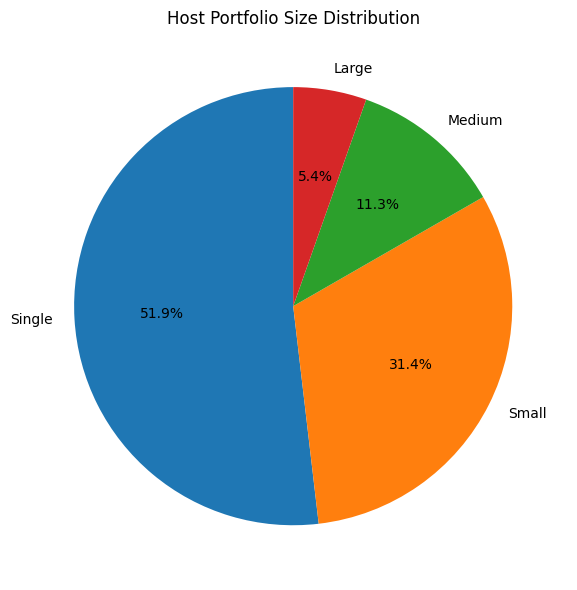

In [ ]:
# Portfolio Size Distribution
portfolio_dist = host_metrics['portfolio_size'].value_counts()

plt.figure(figsize=(8, 6))
plt.pie(portfolio_dist.values, labels=portfolio_dist.index, autopct='%1.1f%%', startangle=90)
plt.title('Host Portfolio Size Distribution')
plt.tight_layout()
plt.show()


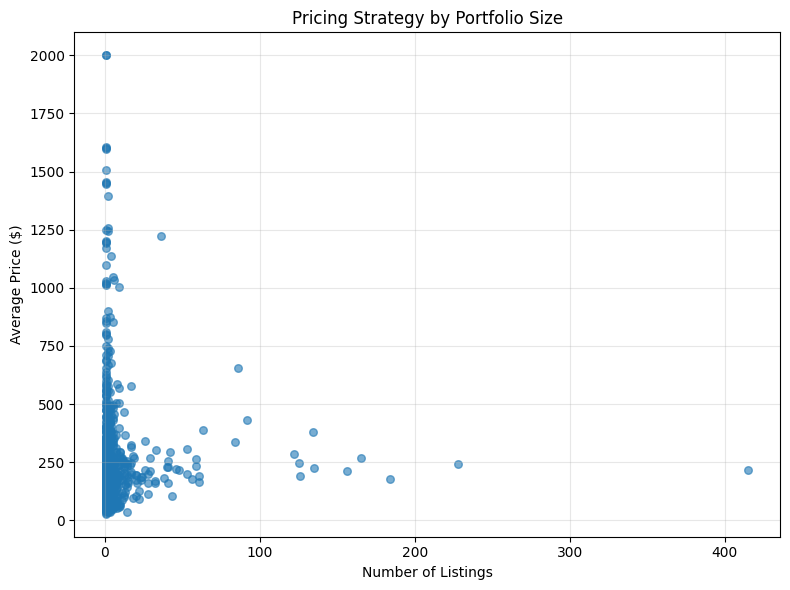

In [ ]:
# Price vs Portfolio Size (Scatter)
sample_hosts = host_metrics.sample(n=min(1000, len(host_metrics)), random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(sample_hosts['listing_count'], sample_hosts['avg_price'], alpha=0.6, s=30)
plt.xlabel('Number of Listings')
plt.ylabel('Average Price ($)')
plt.title('Pricing Strategy by Portfolio Size')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


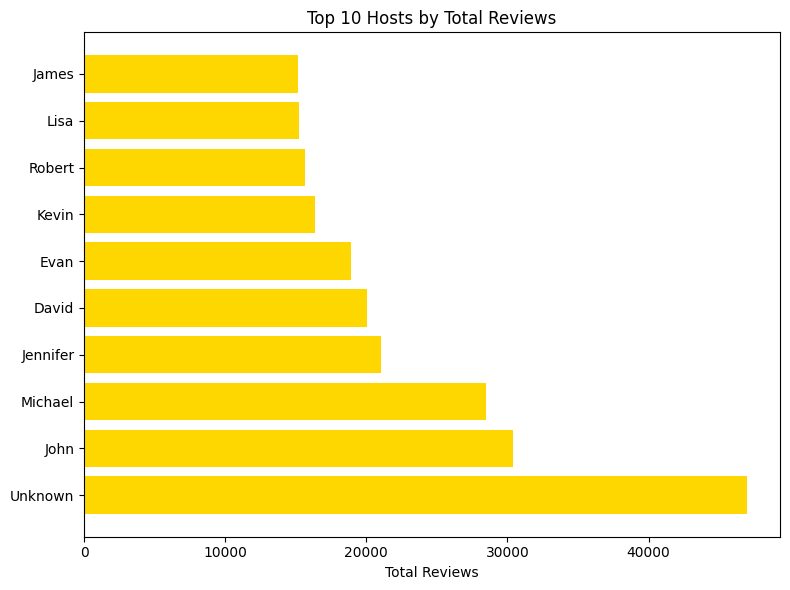

In [ ]:
# Top 10 Hosts by Total Reviews
top_hosts = host_metrics.nlargest(10, 'total_reviews')

plt.figure(figsize=(8, 6))
plt.barh(range(len(top_hosts)), top_hosts['total_reviews'], color='gold')
plt.yticks(range(len(top_hosts)), [name[:15] + '...' if len(name) > 15 else name for name in top_hosts.index])
plt.xlabel('Total Reviews')
plt.title('Top 10 Hosts by Total Reviews')
plt.tight_layout()
plt.show()


####  Temporal Booking Analysis

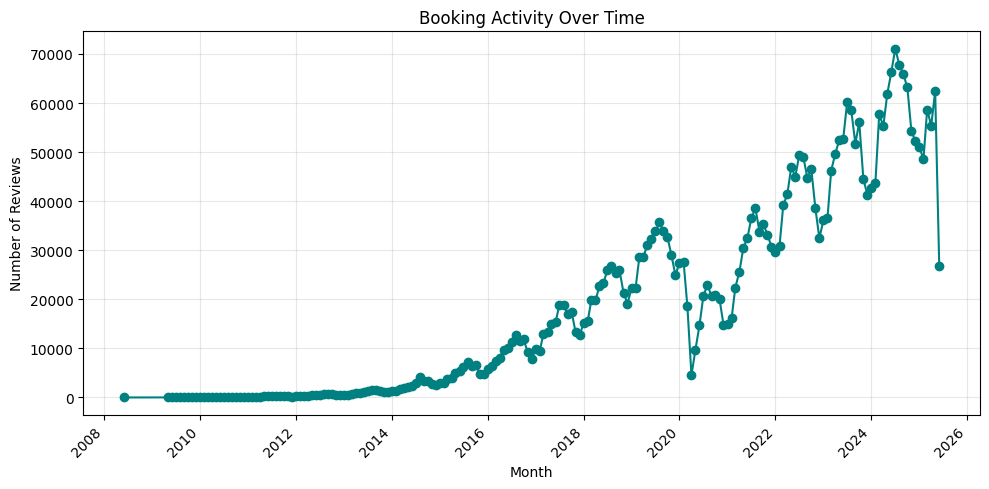

In [ ]:
# Booking Activity Over Time (Monthly Reviews Trend)
reviews_by_month = reviews_df1.groupby(reviews_df1['date'].dt.to_period('M')).size()
reviews_by_month.index = reviews_by_month.index.to_timestamp()

plt.figure(figsize=(10, 5))
reviews_by_month.plot(kind='line', marker='o', color='teal')
plt.title('Booking Activity Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


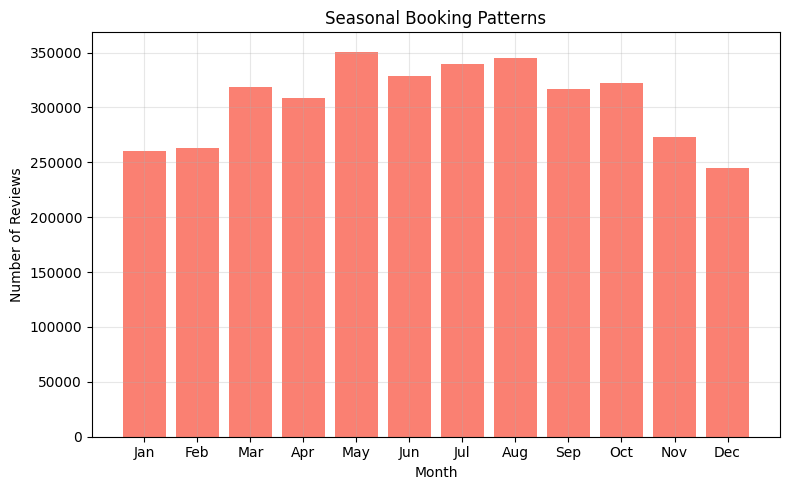

In [ ]:
# Seasonal Booking Patterns (Monthly Total)
reviews_by_month_num = reviews_df1['review_month'].value_counts().sort_index()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(8, 5))
plt.bar(range(1, 13), reviews_by_month_num.values, color='salmon')
plt.title('Seasonal Booking Patterns')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(ticks=range(1, 13), labels=month_names)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

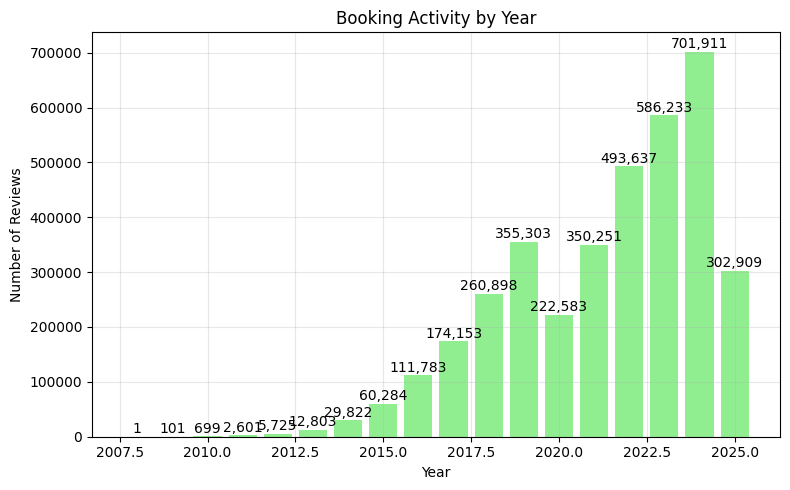

In [ ]:
# Booking Activity by Year
reviews_by_year = reviews_df1['review_year'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(reviews_by_year.index, reviews_by_year.values, color='lightgreen')
plt.title('Booking Activity by Year')
plt.xlabel('Year')
plt.ylabel('Number of Reviews')

# Add value labels
for i, v in enumerate(reviews_by_year.values):
    plt.text(reviews_by_year.index[i], v + 500, f'{v:,}', ha='center', va='bottom')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

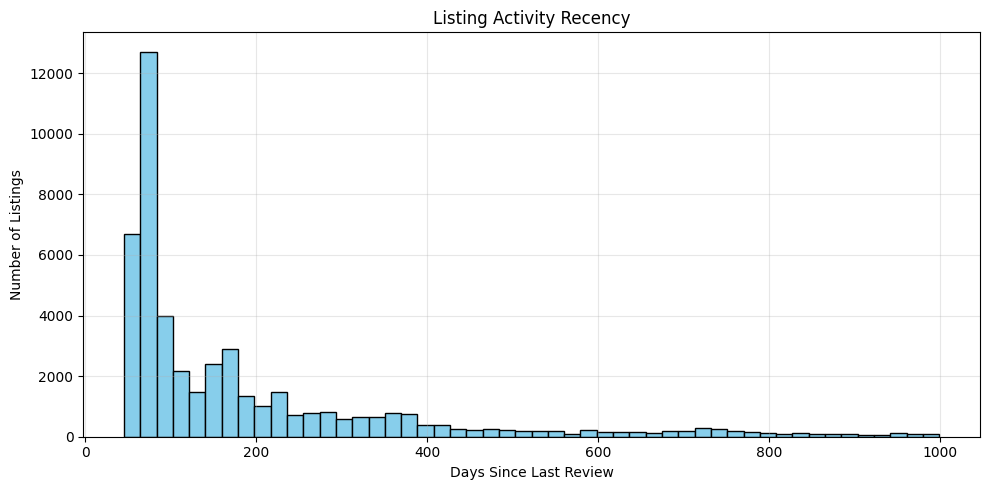

In [ ]:
# Listing Activity Recency (Days Since Last Review)
valid_days = listings_df1['days_since_last_review']
valid_days = valid_days[valid_days < 1000]  # remove outliers or NAs

plt.figure(figsize=(10, 5))
plt.hist(valid_days, bins=50, color='skyblue', edgecolor='black')
plt.title('Listing Activity Recency')
plt.xlabel('Days Since Last Review')
plt.ylabel('Number of Listings')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Amenities (Property Type) Value Analysis

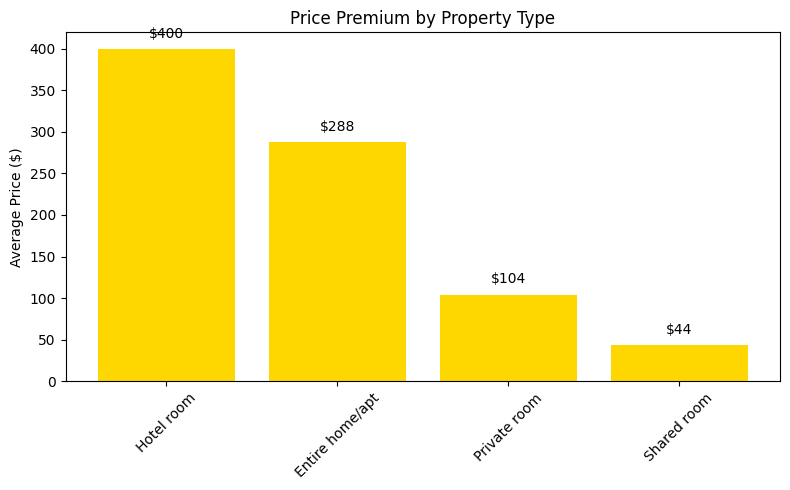

In [ ]:
# Price Premium by Property Type
price_premiums = listings_df1.groupby('room_type')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(price_premiums.index, price_premiums.values, color='gold')
plt.title('Price Premium by Property Type')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=45)

# Add value labels on top of bars
for i, v in enumerate(price_premiums.values):
    plt.text(i, v + 10, f'${v:.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()


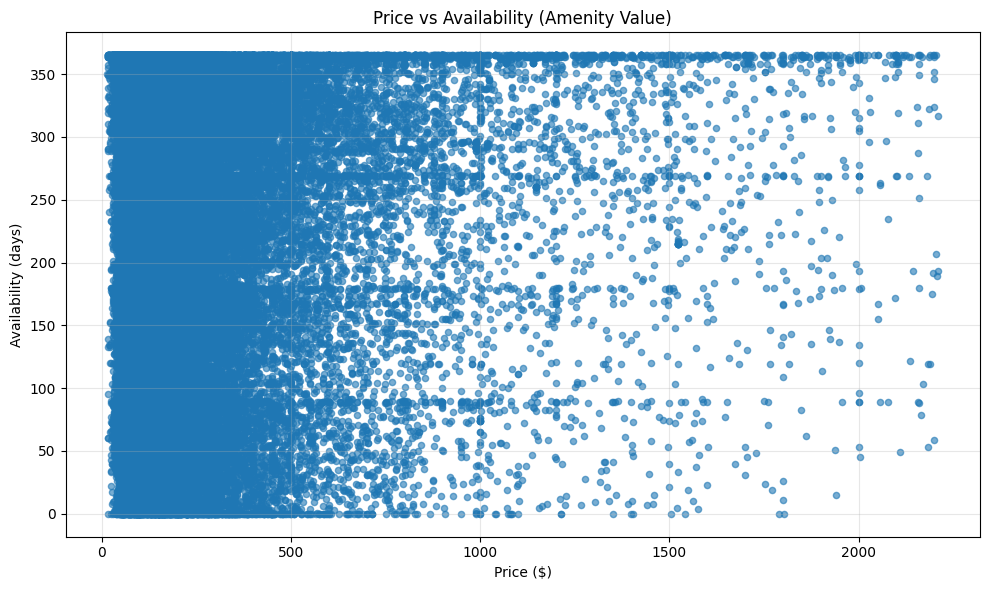

In [ ]:
# Price vs Availability
plt.figure(figsize=(10, 6))
plt.scatter(listings['price'], listings['availability_365'], alpha=0.6, s=20)
plt.xlabel('Price ($)')
plt.ylabel('Availability (days)')
plt.title('Price vs Availability (Amenity Value)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

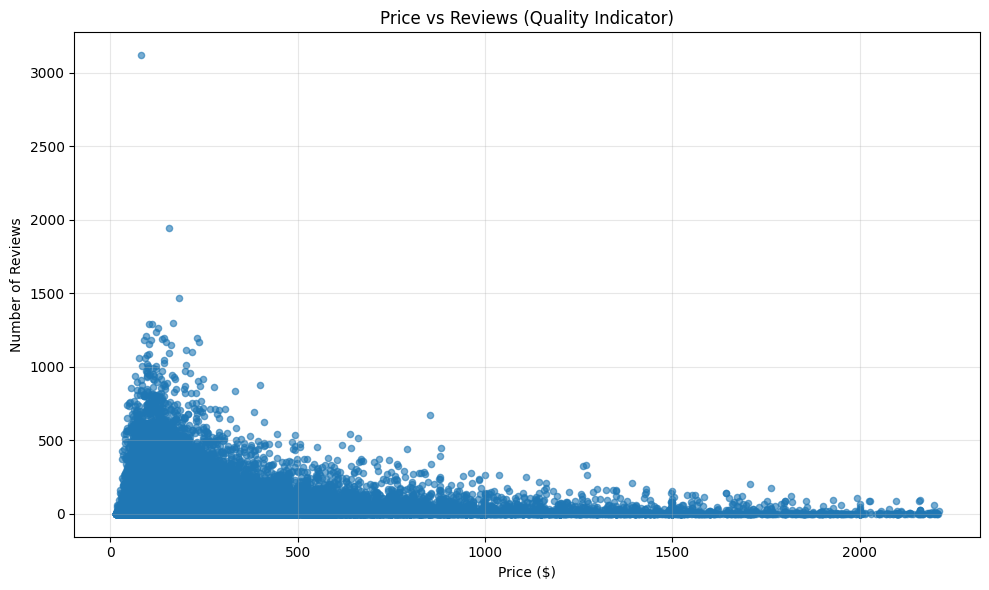

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(listings['price'], listings['number_of_reviews'], alpha=0.6, s=20)
plt.xlabel('Price ($)')
plt.ylabel('Number of Reviews')
plt.title('Price vs Reviews (Quality Indicator)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Guest Behavior & Loyalty Analysis

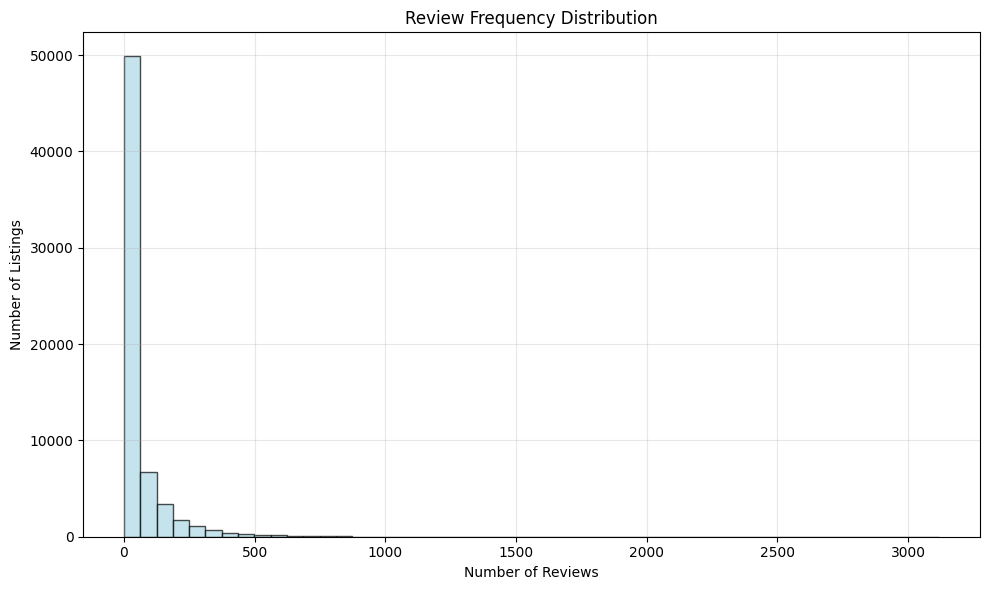

In [ ]:
# Review Frequency Distribution
plt.figure(figsize=(10, 6))
plt.hist(listings_df1['number_of_reviews'], bins=50, alpha=0.7, color='lightblue', edgecolor='black')
plt.title('Review Frequency Distribution')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Listings')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

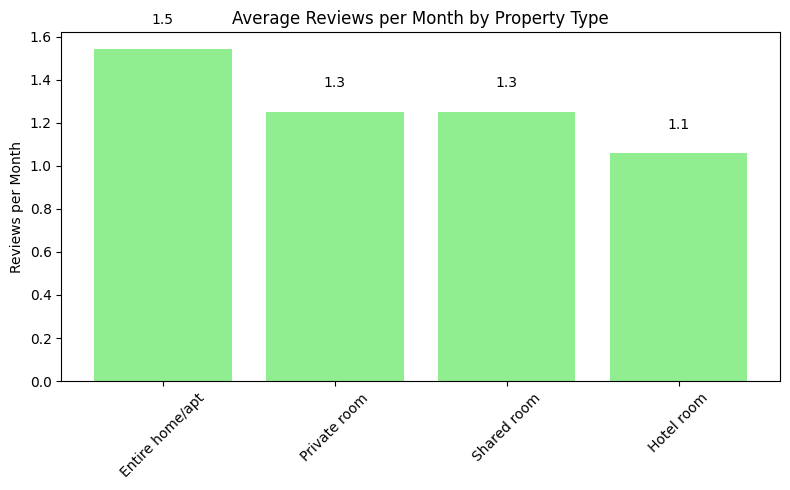

In [ ]:
# Average Reviews per Month by Property Type
reviews_by_room = listings_df1.groupby('room_type')['reviews_per_month'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(reviews_by_room.index, reviews_by_room.values, color='lightgreen')
plt.title('Average Reviews per Month by Property Type')
plt.ylabel('Reviews per Month')
plt.xticks(rotation=45)

# Add value labels
for i, v in enumerate(reviews_by_room.values):
    plt.text(i, v + 0.1, f'{v:.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()


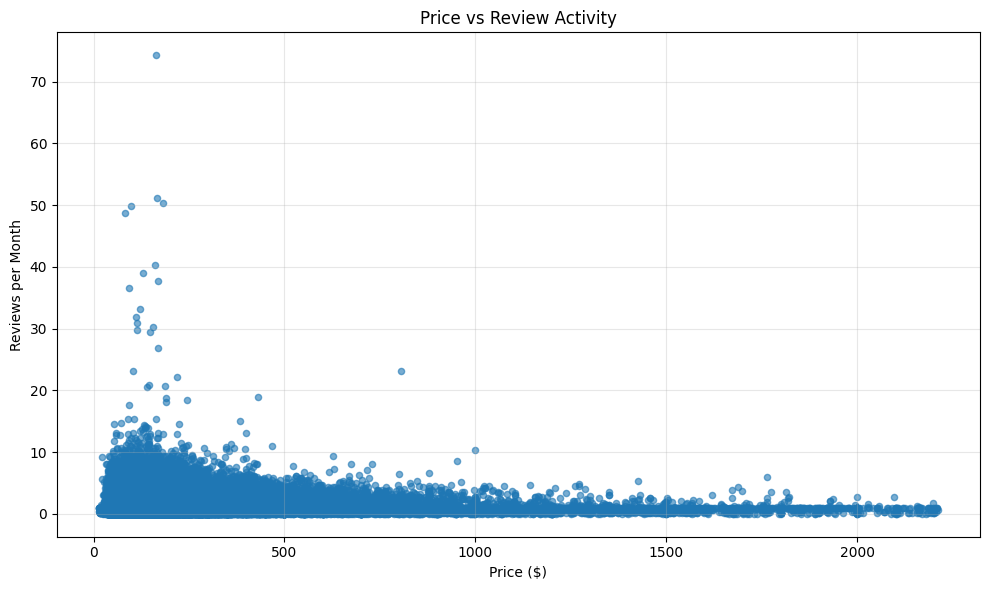

In [ ]:
# Price vs Review Activity Scatter Plot
plt.figure(figsize=(10, 6))
plt.scatter(listings_df1['price'], listings_df1['reviews_per_month'], alpha=0.6, s=20)
plt.xlabel('Price ($)')
plt.ylabel('Reviews per Month')
plt.title('Price vs Review Activity')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

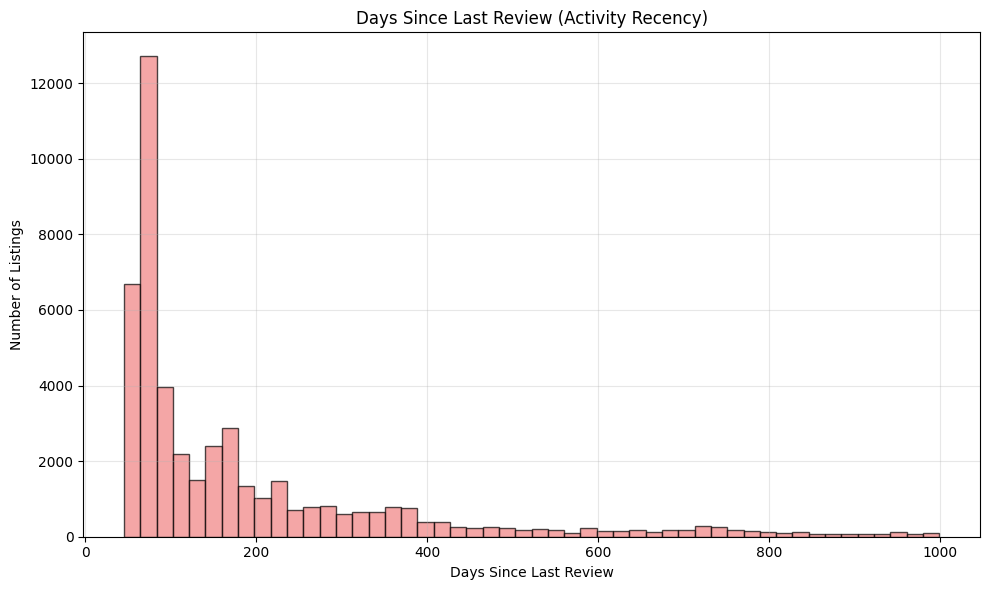

In [ ]:
# Days Since Last Review
valid_days = listings_df1['days_since_last_review'][listings_df1['days_since_last_review'] < 1000]

plt.figure(figsize=(10, 6))
plt.hist(valid_days, bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Days Since Last Review (Activity Recency)')
plt.xlabel('Days Since Last Review')
plt.ylabel('Number of Listings')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Interactive Price Distribution
import plotly.express as px

fig1 = px.histogram(listings_df1, x='price', nbins=50,
                    title='Interactive Price Distribution',
                    labels={'price': 'Price ($)', 'count': 'Number of Listings'},
                    color_discrete_sequence=['skyblue'])
fig1.update_layout(showlegend=False)
fig1.write_html('interactive_price_distribution.html')
fig1.show()


In [ ]:
# Interactive Scatter Plot: Price vs Reviews by Room Type
sample_data = listings_df1.sample(n=min(5000, len(listings_df1)), random_state=42)

fig2 = px.scatter(sample_data, x='number_of_reviews', y='price',
                  color='room_type', size='reviews_per_month',
                  title='Interactive: Price vs Reviews by Room Type',
                  labels={'number_of_reviews': 'Number of Reviews', 'price': 'Price ($)'},
                  hover_data=['neighbourhood', 'host_name'])
fig2.write_html('interactive_price_vs_reviews.html')
fig2.show()

In [ ]:
# Interactive Airbnb Map
fig3 = px.scatter_mapbox(sample_data,
                        lat='latitude', lon='longitude',
                        color='price', size='number_of_reviews',
                        hover_data=['name', 'neighbourhood', 'room_type'],
                        title='Interactive Airbnb Map',
                        mapbox_style='open-street-map',
                        zoom=10)
fig3.write_html('interactive_airbnb_map.html')
fig3.show()


In [ ]:
# Interactive Neighborhood Analysis (Top 20 by Avg Price)
neighborhood_stats = listings_df1.groupby('neighbourhood').agg({
    'price': ['mean', 'count'],
    'number_of_reviews': 'mean'
}).round(2)

neighborhood_stats.columns = ['avg_price', 'listing_count', 'avg_reviews']
neighborhood_stats = neighborhood_stats.reset_index()
neighborhood_stats = neighborhood_stats.sort_values('avg_price', ascending=False).head(20)

fig4 = px.bar(neighborhood_stats, x='neighbourhood', y='avg_price',
              title='Top 20 Neighborhoods by Average Price',
              labels={'avg_price': 'Average Price ($)', 'neighbourhood': 'Neighborhood'},
              hover_data=['listing_count', 'avg_reviews'])
fig4.update_xaxes(tickangle=45)
fig4.write_html('interactive_neighborhood_prices.html')
fig4.show()